## Task Group 0: Reproducible Modeling Setup

## Task Group 0: Reproducible Modeling Setup

### Question

Can the baseline-modeling notebook independently reconstruct the leakage-safe, row-matched modeling datasets established in Phase 1.3 without relying on variables left in memory by the pipeline notebook?

### Why this matters

The Phase 1.3 notebook established several important data-pipeline decisions:

- engines are split at the `unit_no` level,
- cycle-only, raw, and temporal representations use matched observations,
- temporal features are causal and engine-bounded,
- cycles 1-4 are excluded from controlled temporal comparisons,
- identifiers, targets, and future-derived information remain outside `X`,
- and learned preprocessing is deferred to the modeling pipeline.

The modeling notebook should reproduce these outputs from reusable source code rather than depending on notebook variables created in a previous session.

This gives the project a reproducible dependency chain:

raw FD001 files
→ reusable data/feature pipeline
→ modeling-ready datasets
→ modeling experiments

### Why the modeling-data builder starts from raw data

`03_baseline_modeling.ipynb` should not load a dataframe exported from the previous notebook merely because that would be convenient.

Instead, the modeling dataset is reconstructed through the same reusable transformations that define the project:

raw data
→ RUL construction
→ grouped split
→ temporal feature construction
→ temporal-boundary filtering
→ matched modeling representations

This reduces hidden notebook dependencies and gives the data transformation logic a single reusable implementation.

The notebook is responsible for running experiments and interpreting results.

The source modules are responsible for defining how the modeling data are constructed.

In [1]:
# --- Import the dependencies required for baseline modeling ---
#
# What this does:
# Loads the numerical/dataframe libraries and the reusable modeling-data
# builder created from the Phase 1.3 pipeline.
#
# Why this matters:
# This notebook should reconstruct its required inputs from source code rather
# than depending on variables left alive by another notebook.
#
# Concept to focus on:
# Restart Kernel + Run All should be enough to reproduce the experiment setup.

import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from predictive_maintenance.config import (
    DATASET_NAME,
    RANDOM_STATE,
)

from predictive_maintenance.data.modeling import (
    build_fd001_modeling_data,
)

In [2]:
# --- Confirm the notebook is running in the intended project environment ---
#
# What this does:
# Shows which Python interpreter executes the modeling notebook.
#
# Why this matters:
# Reproducibility depends on both the project source code and the environment
# containing its installed dependencies.
#
# Concept to focus on:
# Being inside the correct repository does not guarantee Jupyter is using the
# project's virtual environment.

print("Python executable:")
print(sys.executable)

print("\nDataset:")
print(DATASET_NAME)

print("\nRandom state:")
print(RANDOM_STATE)

Python executable:
/Users/stuart/repos/ml-predictive-maintenance-mlops/.venv/bin/python3

Dataset:
FD001

Random state:
42


In [3]:
# --- Reconstruct all Phase 1.4 modeling inputs from reusable source code ---
#
# What this does:
# Starts from the canonical FD001 files and reproduces the grouped,
# leakage-safe, row-matched development datasets.
#
# Why this matters:
# Phase 1.4 should receive the same data contract every time the notebook is
# executed from a fresh kernel.
#
# Concept to focus on:
# This object is the reproducible boundary between data engineering and
# modeling.

modeling_data = build_fd001_modeling_data()

In [4]:
# --- Create concise aliases for the canonical development datasets ---
#
# What this does:
# Gives the modeling notebook shorter names for the three representations,
# common targets, and engine-group metadata.
#
# Why this matters:
# The aliases improve notebook readability without changing the underlying
# dataset definitions.
#
# Concept to focus on:
# All three X representations share the SAME observations and targets.
# They differ only in the predictive information available to the model.

X_train_cycle = modeling_data.X_train_cycle
X_validation_cycle = modeling_data.X_validation_cycle

X_train_raw = modeling_data.X_train_raw
X_validation_raw = modeling_data.X_validation_raw

X_train_temporal = modeling_data.X_train_temporal
X_validation_temporal = modeling_data.X_validation_temporal

y_train = modeling_data.y_train
y_validation = modeling_data.y_validation

groups_train = modeling_data.groups_train
groups_validation = modeling_data.groups_validation

In [5]:
# --- Inspect the reproducible Phase 1.4 modeling representations ---
#
# What this does:
# Summarizes the three controlled feature representations entering modeling.
#
# Why this matters:
# The dimensionality should differ intentionally while the observation
# population remains fixed.
#
# Concept to focus on:
# We are changing WHAT the model knows, not WHICH observations it is tested on.

modeling_inventory = pd.DataFrame(
    [
        {
            "representation": "cycle_only",
            "train_rows": len(X_train_cycle),
            "validation_rows": len(
                X_validation_cycle
            ),
            "features": X_train_cycle.shape[1],
        },
        {
            "representation": "raw",
            "train_rows": len(X_train_raw),
            "validation_rows": len(
                X_validation_raw
            ),
            "features": X_train_raw.shape[1],
        },
        {
            "representation": "temporal",
            "train_rows": len(
                X_train_temporal
            ),
            "validation_rows": len(
                X_validation_temporal
            ),
            "features": (
                X_train_temporal.shape[1]
            ),
        },
    ]
)

modeling_inventory

,representation,train_rows,validation_rows,features
0,cycle_only,16241,3990,1
1,raw,16241,3990,18
2,temporal,16241,3990,36


In [6]:
# --- Verify that all representations describe the same engine-cycle observations ---
#
# What this does:
# Checks that cycle-only, raw, temporal, y, and group metadata share the same
# row indices.
#
# Why this matters:
# Our Phase 1.4 comparisons are meaningful only if the models receive
# different features for the SAME prediction problems.
#
# Concept to focus on:
# Same number of rows is weaker than same row identity.

assert X_train_cycle.index.equals(
    X_train_raw.index
)

assert X_train_cycle.index.equals(
    X_train_temporal.index
)

assert X_train_cycle.index.equals(
    y_train.index
)

assert X_train_cycle.index.equals(
    groups_train.index
)


assert X_validation_cycle.index.equals(
    X_validation_raw.index
)

assert X_validation_cycle.index.equals(
    X_validation_temporal.index
)

assert X_validation_cycle.index.equals(
    y_validation.index
)

assert X_validation_cycle.index.equals(
    groups_validation.index
)

print(
    "Cycle-only, raw, temporal, target, and group rows are aligned."
)

Cycle-only, raw, temporal, target, and group rows are aligned.


In [7]:
# --- Verify that the reproduced validation set still contains unseen engines ---
#
# What this does:
# Confirms that no engine identity appears in both training and validation.
#
# Why this matters:
# Every performance metric in Phase 1.4 depends on validation representing
# generalization to engines absent from model fitting.
#
# Concept to focus on:
# Modeling should fail immediately if the grouped-validation contract is lost.

training_engines = set(
    groups_train.unique()
)

validation_engines = set(
    groups_validation.unique()
)

engine_overlap = (
    training_engines
    .intersection(validation_engines)
)

assert not engine_overlap

print(
    "Training engines:",
    len(training_engines),
)

print(
    "Validation engines:",
    len(validation_engines),
)

print(
    "Engine overlap:",
    len(engine_overlap),
)

Training engines: 80
Validation engines: 20
Engine overlap: 0


In [8]:
# --- Verify that all development model inputs are finite and complete ---
#
# What this does:
# Ensures that Phase 1.3 boundary handling produced matrices with no NaNs or
# infinite values.
#
# Why this matters:
# Phase 1.4 should start from known-good model inputs rather than discovering
# basic pipeline problems while fitting estimators.
#
# Concept to focus on:
# Task Group 0 verifies the data contract; later task groups evaluate models.

development_matrices = {
    "train_cycle": X_train_cycle,
    "validation_cycle": X_validation_cycle,
    "train_raw": X_train_raw,
    "validation_raw": X_validation_raw,
    "train_temporal": X_train_temporal,
    "validation_temporal": X_validation_temporal,
}

for name, matrix in development_matrices.items():
    assert not matrix.isna().any().any(), (
        f"{name} contains NaNs."
    )

    assert np.isfinite(
        matrix.to_numpy()
    ).all(), (
        f"{name} contains non-finite values."
    )

print(
    "All Phase 1.4 development matrices are numerically ready."
)

All Phase 1.4 development matrices are numerically ready.


In [9]:
# --- Verify that repeated construction produces the same development split ---
#
# What this does:
# Rebuilds the modeling datasets using the same configuration and compares
# their indices.
#
# Why this matters:
# RANDOM_STATE should make the randomized grouped engine assignment
# reproducible across fresh notebook runs.
#
# Concept to focus on:
# Reproducibility means rerunning the pipeline recreates the same experiment,
# not merely something with the same approximate dimensions.

repeat_modeling_data = (
    build_fd001_modeling_data()
)

assert modeling_data.X_train_raw.index.equals(
    repeat_modeling_data.X_train_raw.index
)

assert (
    modeling_data.X_validation_raw.index.equals(
        repeat_modeling_data.X_validation_raw.index
    )
)

assert modeling_data.groups_train.equals(
    repeat_modeling_data.groups_train
)

assert modeling_data.groups_validation.equals(
    repeat_modeling_data.groups_validation
)

print(
    "Modeling-data construction is reproducible."
)

Modeling-data construction is reproducible.


In [10]:
# --- Confirm that Phase 1.4 exposes test inputs but not official test answers ---
#
# What this does:
# Verifies that the modeling-data object contains official endpoint FEATURES
# while intentionally providing no test-RUL target attribute.
#
# Why this matters:
# Phase 1.4 may prepare inference-compatible inputs, but official endpoint
# labels must not influence model development.
#
# Concept to focus on:
# Test inputs and test answers have fundamentally different roles.

assert len(
    modeling_data.X_test_endpoint_raw
) == 100

assert len(
    modeling_data.X_test_endpoint_temporal
) == 100

assert not hasattr(
    modeling_data,
    "test_rul",
)

assert not hasattr(
    modeling_data,
    "test_rul_df",
)

print(
    "Official test endpoint inputs are available; test answers remain outside "
    "the Phase 1.4 modeling contract."
)

Official test endpoint inputs are available; test answers remain outside the Phase 1.4 modeling contract.


### Canonical Phase 1.4 inputs remain unscaled

The matrices reconstructed in this task group are the canonical modeling inputs.

They should not be globally standardized before modeling begins.

Different estimators have different preprocessing requirements, and any learned preprocessing must occur inside the relevant training boundary.

For example, a linear model may later use:

`StandardScaler → Ridge`

inside a scikit-learn `Pipeline`.

A tree-based model may not require standardization at all.

Keeping the canonical data unscaled lets each experiment define its preprocessing correctly without introducing cross-validation leakage.

In [11]:
# --- Run the final Phase 1.4 setup audit ---
#
# What this does:
# Combines the critical reproducibility, alignment, grouping, feature-count,
# and numerical-readiness checks required before evaluation code is written.
#
# Why this matters:
# Once this passes, subsequent task groups can focus on modeling questions
# rather than silently rebuilding or changing the dataset.
#
# Concept to focus on:
# Task Group 0 freezes the experimental DATA contract.

assert X_train_cycle.shape[1] == 1
assert X_train_raw.shape[1] == 18
assert X_train_temporal.shape[1] == 36

assert X_train_cycle.index.equals(
    X_train_raw.index
)
assert X_train_cycle.index.equals(
    X_train_temporal.index
)

assert X_validation_cycle.index.equals(
    X_validation_raw.index
)
assert X_validation_cycle.index.equals(
    X_validation_temporal.index
)

assert X_train_cycle.index.equals(
    y_train.index
)
assert X_validation_cycle.index.equals(
    y_validation.index
)

assert set(
    groups_train.unique()
).isdisjoint(
    set(groups_validation.unique())
)

for matrix in development_matrices.values():
    assert np.isfinite(
        matrix.to_numpy()
    ).all()

print(
    "Phase 1.4 Task Group 0 modeling setup is ready."
)

Phase 1.4 Task Group 0 modeling setup is ready.


### Task Group 0 — Interpretation Questions

1. **Why should `03_baseline_modeling.ipynb` reconstruct its modeling datasets through reusable source code instead of depending on variables created in `02_baseline_pipeline.ipynb`?**

We have not created any models yet, so reproducibility is critical. If starting a new phase of the project in a new notebook, then we need to recreate the relevant results of the previous sections and verify them before going deep into this section.

2. **Why do the cycle-only, raw, and temporal matrices intentionally have 1, 18, and 36 columns while still requiring identical row indices and targets?**

Each feature set will be used to answer a distinct question and provide valuable comparison data. In order to make the comparison as valid as possible, it's important that row matching be enforced.

*The representations intentionally have different dimensionalities because each tests a different information set. They use identical engine-cycle rows and targets so that feature information is the primary experimental variable.*

3. **Why is checking identical row indices stronger than merely checking that `X` and `y` have the same number of rows?**

Checking identical row indices will also ensure that cycle counts are aligned. If we only checked dimensions, it's plausbile that rows could be switched around within engines, which would negatively impact our comparison data. 

*Equal lengths prove only that X and y contain the same number of observations. Identical indices help verify that each feature row is paired with the correct target and engine metadata after sorting or filtering operations.*

4. **Why does the Phase 1.4 modeling-data object expose official test endpoint features but deliberately not expose `test_rul_df`?**

Features are still measured at the final cycle of an engine, or in the case of the test set the cutoff after which the data ends but the engine still continues functioning. Having access to endpoint features is important for the training process and boosting predictive capabilities. Having access to `test_rul_df` would cause leakage. 

*Test features are observable inference inputs. Test RUL values are the answers used to judge the final system.*

*The modeling-data object exposes official test endpoint features because they contain only information that would be available at inference time and will eventually be supplied to the finalized model. It deliberately hides `test_rul_df` because those are the correct
endpoint answers, and allowing them to influence feature engineering, model selection, preprocessing, or hyperparameters would invalidate the final test evaluation.*

*The official test endpoint features are not used for training. They are eventually used for inference after the model is finalized.*

5. **Why should the modeling-ready matrices remain unscaled at the end of Task Group 0, even though some of the models we will train later will require standardization?**

Because these matrices will be used for different cross-validation folds. We need a consistent starting set that can repeatedly be used. If standardization was applied there are situations where we would need to undo the standardization before carrying out other parts of the preprocessing.

*The important issue is where the scaler learns its parameters.*

*The canonical matrices remain unscaled so any learned preprocessing can be fitted inside the correct training boundary for each model or validation fold. Pre-scaling the entire development dataset could leak validation information into preprocessing.*

**Official test endpoint features are for eventual inference, not for training.**

**Canonical matrices stay unscaled so learned preprocessing can be fitted separately inside each training/validation boundary.**

## Task Group 1: Evaluation Contract & Metrics

## Task Group 1: Evaluation Contract & Metrics

### Question

How should baseline RUL prediction performance be measured so that models can be compared consistently, while still distinguishing typical prediction error from occasional large mistakes?

### Why this matters

A model score has meaning only relative to a clearly defined evaluation procedure.

Before training models, Phase 1.4 should establish:

- which observations are used for evaluation,
- which target is scored,
- which metrics are calculated,
- what direction indicates improvement,
- and which dataset may influence model-development decisions.

For baseline development:

- models are fitted using development-training engines,
- performance is evaluated on held-out validation engines,
- direct representation comparisons use the matched validation rows,
- RMSE and MAE are calculated from the same predictions,
- and the official test RUL labels remain outside model development.

Defining these rules before looking at model scores reduces the risk of changing the evaluation procedure to favor a particular result.

### Prediction-error convention

For diagnostic purposes, we will define signed prediction error as:

`prediction_error = predicted_rul - actual_rul`

Therefore:

- positive error = the model predicts too much remaining life,
- negative error = the model predicts too little remaining life,
- zero error = exact prediction.

MAE and RMSE discard this sign when aggregating error magnitude, but preserving signed errors will be useful later when diagnosing model behavior.

### Mean Absolute Error — MAE

MAE calculates the average absolute distance between predictions and their true RUL values.

Conceptually:

`MAE = mean(abs(predicted_rul - actual_rul))`

If MAE = 20, a useful interpretation is:

"Predictions are about 20 RUL cycles away from the true value on average."

MAE treats errors proportionally.

An error of 20 contributes twice as much as an error of 10.

### Root Mean Squared Error — RMSE

RMSE squares each prediction error before averaging and then takes the square root.

Conceptually:

`RMSE = sqrt(mean((predicted_rul - actual_rul) ** 2))`

Because errors are squared, large mistakes contribute disproportionately more than small mistakes.

RMSE is therefore useful when large RUL prediction failures are especially undesirable.

Like MAE, RMSE remains expressed in RUL-cycle units.

In [12]:
# --- Compare MAE and RMSE when one prediction is much worse than the others ---
#
# What this does:
# Creates a tiny example where three predictions are perfect and one prediction
# has a large error.
#
# Why this matters:
# MAE and RMSE summarize the same predictions differently. RMSE places greater
# emphasis on unusually large misses.
#
# Concept to focus on:
# The choice of metric expresses what kinds of prediction mistakes matter.

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)

example_actual = np.array(
    [100, 80, 60, 40]
)

example_predicted = np.array(
    [100, 80, 60, 80]
)

example_mae = mean_absolute_error(
    example_actual,
    example_predicted,
)

example_rmse = np.sqrt(
    mean_squared_error(
        example_actual,
        example_predicted,
    )
)

print(
    "MAE:",
    example_mae,
)

print(
    "RMSE:",
    example_rmse,
)

MAE: 10.0
RMSE: 20.0


### Phase 1.4 metric policy

For baseline model development:

**Primary metric: RMSE**

RMSE will be the main metric used when comparing model performance because it penalizes large RUL prediction errors more strongly.

**Secondary metric: MAE**

MAE will provide an intuitive measure of typical absolute RUL error and help determine whether RMSE is being driven by a smaller number of large misses.

For both metrics:

**lower is better.**

Training metrics may also be reported for diagnostic purposes, but validation performance is the primary evidence of generalization.

**Training error tells us how well the model fit. Validation error tells us much more about whether the model generalized.**

### Why metric calculation belongs in reusable source code

Model comparisons should not independently reimplement scoring logic in different notebook cells.

A single evaluation utility gives the project one definition of:

- RMSE,
- MAE,
- signed prediction error,
- and prediction-result structure.

This reduces the risk that two experiments accidentally calculate nominally identical metrics in different ways.

The notebook remains responsible for interpreting the scores.

In [13]:
# --- Import the canonical Phase 1.4 regression evaluation utilities ---
#
# What this does:
# Loads the shared metric definitions and prediction-result constructor.
#
# Why this matters:
# Every baseline model should be judged using the same metric implementation.
#
# Concept to focus on:
# The evaluation function is part of the experimental contract.

from predictive_maintenance.models.evaluation import (
    build_prediction_frame,
    calculate_regression_metrics,
)

In [14]:
# --- Verify that perfect predictions produce zero error ---
#
# What this does:
# Tests the evaluation utility against a case whose correct result is known.
#
# Why this matters:
# Before trusting model metrics, we should verify the metric implementation on
# simple inputs with predictable behavior.
#
# Concept to focus on:
# A small known-answer test can detect evaluation-code mistakes before those
# mistakes contaminate every experiment.

perfect_actual = np.array(
    [100, 75, 50, 25, 0]
)

perfect_predicted = np.array(
    [100, 75, 50, 25, 0]
)

perfect_metrics = (
    calculate_regression_metrics(
        perfect_actual,
        perfect_predicted,
    )
)

print(
    perfect_metrics
)

assert perfect_metrics.rmse == 0
assert perfect_metrics.mae == 0

RegressionMetrics(rmse=0.0, mae=0.0)


In [15]:
# --- Verify the meaning of positive and negative signed prediction errors ---
#
# What this does:
# Creates one overprediction and one underprediction and checks the resulting
# signed errors.
#
# Why this matters:
# Later diagnostic plots depend on a consistent interpretation of error sign.
#
# Concept to focus on:
# Positive error means predicted RUL was too high.
# Negative error means predicted RUL was too low.

sign_demo = build_prediction_frame(
    y_true=pd.Series(
        [40, 40]
    ),
    y_pred=np.array(
        [55, 25]
    ),
)

sign_demo

,actual_rul,predicted_rul,prediction_error,absolute_error
0,40,55,15,15
1,40,25,-15,15


In [16]:
assert (
    sign_demo["prediction_error"]
    .tolist()
    == [15, -15]
)

print(
    "Prediction-error sign convention verified."
)

Prediction-error sign convention verified.


### Development metrics versus final test metrics

The Phase 1.4 models will be evaluated using the held-out validation engines created from the complete development-training data.

These validation scores may influence decisions such as:

- which feature representation performs better,
- which model family deserves further exploration,
- and which experiments should be prioritized in Phase 1.5.

The official test endpoint RUL labels cannot serve this role because repeatedly using them for development decisions would turn the test set into another validation set.

The official test score is reserved for the finalized pipeline after model-development decisions are complete.

In [17]:
# --- Define the structure used to compare baseline modeling experiments ---
#
# What this does:
# Creates an empty table with the information every baseline experiment should
# eventually report.
#
# Why this matters:
# A consistent results schema makes comparisons easier and discourages
# selectively reporting only favorable metrics.
#
# Concept to focus on:
# We decide what gets reported BEFORE seeing which model performs best.

BASELINE_RESULT_COLUMNS = [
    "model",
    "representation",
    "n_features",
    "train_rmse",
    "validation_rmse",
    "train_mae",
    "validation_mae",
]

baseline_results = pd.DataFrame(
    columns=BASELINE_RESULT_COLUMNS
)

baseline_results

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae


### Interpreting RMSE and MAE together

RMSE and MAE answer related but different questions.

If RMSE and MAE are relatively close, prediction errors may be reasonably consistent.

If RMSE is substantially larger than MAE, a smaller number of large prediction mistakes may be contributing heavily to the score.

For example:

Model A:

- MAE = 15
- RMSE = 17

Model B:

- MAE = 15
- RMSE = 30

Both have the same average absolute error, but Model B appears to suffer from much more severe large misses.

Later error diagnostics will inspect those mistakes directly rather than relying only on aggregate metrics.

### Training performance is diagnostic, not the primary selection criterion

A sufficiently flexible model can often reduce training error by fitting the development-training observations more closely.

That does not guarantee better performance on unseen engines.

The relationship between training and validation error can help diagnose model behavior:

- high training error + high validation error may suggest underfitting,
- low training error + much higher validation error may suggest overfitting,
- similar and comparatively low errors are generally more encouraging.

Model comparisons should therefore prioritize validation performance while using the train-validation gap as diagnostic information.

In [18]:
# --- Verify the Phase 1.4 evaluation contract before fitting any model ---
#
# What this does:
# Confirms that the common train/validation targets remain aligned with all
# matched feature representations and that official test answers are not part
# of the notebook's development objects.
#
# Why this matters:
# Metric consistency is useful only if the predictions being scored correspond
# to the same controlled validation population.
#
# Concept to focus on:
# Evaluation correctness requires both a consistent metric and a consistent
# population.

assert X_train_cycle.index.equals(
    y_train.index
)

assert X_train_raw.index.equals(
    y_train.index
)

assert X_train_temporal.index.equals(
    y_train.index
)

assert X_validation_cycle.index.equals(
    y_validation.index
)

assert X_validation_raw.index.equals(
    y_validation.index
)

assert X_validation_temporal.index.equals(
    y_validation.index
)

assert not hasattr(
    modeling_data,
    "test_rul_df",
)

print(
    "Phase 1.4 evaluation contract is ready."
)

Phase 1.4 evaluation contract is ready.


### Task Group 1 — Interpretation Questions

1. **What different information do MAE and RMSE provide, and why can RMSE become substantially larger than MAE when a model makes a few severe prediction errors?**

MAE provides the mean of the absolute errors. RMSE provides the square root of the average of the squared errors. RMSE winds up having much larger values if there are extreme outliers because it increases as the square of the different rather than linearly.

*MAE is the average absolute prediction error and treats error magnitude linearly. RMSE squares error before averaging, so large prediction misses receive disproportionately greater weight, and then takes the square root so the final metric remains in RUL-cycle units.*

2. **Why are validation metrics more important for model comparison than training metrics, and what can the gap between training and validation error tell us?**

Validation metrics tell us how well a model will generalize to unseen data before we put in through the final test. If there is a gap between training and validation error, then there's a difference between how well the model did on the training set and how well it did on the cross-validation set. 

*Validation metrics estimate how well a model generalizes to unseen engines from a similar population.*

*Validation error is more important for model comparison because it measures performance on engines excluded from fitting. Training error shows how well the model fits known data. A large train-validation gap can indicate overfitting, while similarly high training and validation errors can indicate underfitting.*

3. **Using our signed-error convention, what does a prediction error of +20 mean? What does -20 mean?**

+20 means the model overestimated the RUL by 20 cycles while -20 means the model underestimated the RUL by 20 cycles.

4. **Why do we define the evaluation metrics and results-table structure before fitting the first model rather than deciding what to report after seeing the results?**

It will allow us to have the same table of metrics for each model that we're training, allowing for better planning before comparison time.

*We want to prevent selective evaluation and establish that every model will be evaluated under the same rules.*

*We define the evaluation contract before seeing model results so every experiment is judged consistently and we cannot selectively change metrics or reporting based on which results make a particular model look best.*

5. **Why can the held-out validation RUL values influence Phase 1.4 model-development decisions while the official `test_rul_df` values cannot?**

Because the held-out validation RUL values are used for inference, not for testing. Using those doesn't count as creating a leakage situation. `test_rul_df` being available at training time would leak rul information into the training process because it's precisely the quantity we're trying to predict. There's a difference between performing testing and performing inference.

*Train learns. Validation chooses. Test judges.*

*Validation RUL values are intentionally used during development to score models and make model-selection decisions. The official test RUL values must remain unused because they are reserved for a final unbiased estimate of the chosen system's performance.*

**MAE tells us about typical absolute error. RMSE reacts more strongly to large mistakes. Validation metrics judge generalization, while the train-validation gap helps diagnose how the model is fitting.**

## Task Group 2: Naive & Cycle-only Benchmarks

## Task Group 2: Naive & Cycle-Only Benchmarks

### Question

How much RUL prediction performance can be achieved with almost no predictive information, and how much additional performance can be obtained using only the engine's current cycle number?

### Why this matters

A model score is difficult to interpret without a reference point.

For example, a validation RMSE of 30 might represent:

- a major improvement over a naive predictor,
- almost no improvement,
- or worse performance than a trivial strategy.

We will therefore establish two simple benchmarks before using sensor measurements.

**Naive mean predictor**

Predict the same RUL value for every observation.

This answers:

"How well can we perform without using the predictive features at all?"

**Cycle-only linear model**

Predict RUL using only the current operating-cycle index.

This answers:

"How much predictive information is available from observable engine age alone?"

Later models using 18 raw features and 36 temporal features should be judged relative to these simpler references.

In [19]:
from sklearn.dummy import DummyRegressor

In [20]:
DummyRegressor(
    strategy="mean"
)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None


In [21]:
# --- Fit a naive mean-RUL benchmark using training targets only ---
#
# What this does:
# Learns one constant prediction: the mean RUL of the development-training
# observations.
#
# Why this matters:
# Every real model should demonstrate that its predictive inputs provide value
# beyond simply guessing a typical training RUL.
#
# Concept to focus on:
# Even a DummyRegressor has a `fit()` step.
# Its constant prediction must be learned from TRAINING targets only.

dummy_model = DummyRegressor(
    strategy="mean"
)

dummy_model.fit(
    X_train_cycle,
    y_train,
)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None


In [22]:
# --- Inspect the constant RUL prediction learned by the naive model ---
#
# What this does:
# Displays the training-target mean that DummyRegressor will predict for every
# observation.
#
# Why this matters:
# A benchmark should be understandable rather than treated as a black box.
#
# Concept to focus on:
# The model has learned nothing about cycle count or sensors.
# It has learned only the central level of the training target.

dummy_prediction_value = float(
    dummy_model.constant_.ravel()[0]
)

print(
    "Dummy prediction for every observation:",
    dummy_prediction_value,
)

print(
    "Training mean RUL:",
    y_train.mean(),
)

assert np.isclose(
    dummy_prediction_value,
    y_train.mean(),
)

Dummy prediction for every observation: 106.48365248445293
Training mean RUL: 106.48365248445293


In [23]:
# --- Generate training and validation predictions from the naive benchmark ---
#
# What this does:
# Applies the training-fitted constant predictor to both development
# populations.
#
# Why this matters:
# We calculate training and validation metrics using exactly the same
# evaluation contract defined in Task Group 1.
#
# Concept to focus on:
# Validation targets are used to SCORE predictions, not to construct them.

dummy_train_predictions = dummy_model.predict(
    X_train_cycle
)

dummy_validation_predictions = dummy_model.predict(
    X_validation_cycle
)

In [24]:
# --- Verify that the dummy model really predicts one value everywhere ---

print(
    "Unique training predictions:",
    np.unique(dummy_train_predictions),
)

print(
    "Unique validation predictions:",
    np.unique(dummy_validation_predictions),
)

Unique training predictions: [106.48365248]
Unique validation predictions: [106.48365248]


In [25]:
# --- Evaluate naive training and validation performance ---
#
# What this does:
# Calculates the canonical RMSE and MAE metrics for the constant predictor.
#
# Why this matters:
# These scores establish the minimum reference against which useful models
# should demonstrate improvement.
#
# Concept to focus on:
# A baseline metric is meaningful even when the underlying model is trivial.

dummy_train_metrics = calculate_regression_metrics(
    y_train,
    dummy_train_predictions,
)

dummy_validation_metrics = calculate_regression_metrics(
    y_validation,
    dummy_validation_predictions,
)

print(
    "Training:",
    dummy_train_metrics,
)

print(
    "Validation:",
    dummy_validation_metrics,
)

Training: RegressionMetrics(rmse=68.66907707999971, mae=56.37830986600789)
Validation: RegressionMetrics(rmse=64.68286393624578, mae=54.46096722318079)


In [26]:
# --- Add the naive benchmark to the shared baseline-results table ---
#
# What this does:
# Records both training and validation metrics using the results schema defined
# before any models were fitted.
#
# Why this matters:
# Every later baseline will be reported using exactly the same metric contract.

dummy_result = pd.DataFrame(
    [
        {
            "model": "DummyRegressor(mean)",
            "representation": "naive",
            "n_features": 0,
            "train_rmse": dummy_train_metrics.rmse,
            "validation_rmse": (
                dummy_validation_metrics.rmse
            ),
            "train_mae": dummy_train_metrics.mae,
            "validation_mae": (
                dummy_validation_metrics.mae
            ),
        }
    ]
)

baseline_results = pd.concat(
    [
        baseline_results,
        dummy_result,
    ],
    ignore_index=True,
)

baseline_results

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967


In [27]:
# --- Fit the first predictive benchmark using current cycle only ---
#
# What this does:
# Learns a linear relationship between the observable current engine cycle and
# training RUL.
#
# Why this matters:
# This provides a simple reference for how much predictive signal is available
# from engine age before sensors or operating settings are introduced.
#
# Concept to focus on:
# The model receives exactly ONE predictive variable: `cycles`.

from sklearn.linear_model import LinearRegression

cycle_model = LinearRegression()

cycle_model.fit(
    X_train_cycle,
    y_train,
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [28]:
# --- Inspect the cycle-only model's fitted intercept and coefficient ---
#
# What this does:
# Shows the linear equation learned from training engines.
#
# Why this matters:
# A one-feature linear benchmark is highly interpretable.
#
# Concept to focus on:
# The cycle coefficient estimates how predicted RUL changes as current cycle
# increases by one unit, according to this population-level linear model.

cycle_intercept = float(
    cycle_model.intercept_
)

cycle_coefficient = float(
    cycle_model.coef_[0]
)

print(
    "Intercept:",
    cycle_intercept,
)

print(
    "Cycle coefficient:",
    cycle_coefficient,
)

Intercept: 186.037567925986
Cycle coefficient: -0.7135926538882222


In [29]:
# --- Generate RUL predictions using only current cycle number ---
#
# What this does:
# Applies the fitted cycle-to-RUL relationship to both development-training
# and unseen validation engines.
#
# Why this matters:
# Comparing these predictions with the dummy benchmark tells us whether cycle
# count contains useful generalizable information.

cycle_train_predictions = cycle_model.predict(
    X_train_cycle
)

cycle_validation_predictions = cycle_model.predict(
    X_validation_cycle
)

In [30]:
# --- Evaluate the cycle-only benchmark using the canonical metrics ---
#
# What this does:
# Calculates RMSE and MAE on both fitted and unseen-engine observations.
#
# Why this matters:
# We now have the first meaningful comparison against the naive baseline.
#
# Concept to focus on:
# Validation improvement over DummyRegressor indicates that current cycle
# contains predictive information that generalizes beyond the training engines.

cycle_train_metrics = calculate_regression_metrics(
    y_train,
    cycle_train_predictions,
)

cycle_validation_metrics = calculate_regression_metrics(
    y_validation,
    cycle_validation_predictions,
)

print(
    "Training:",
    cycle_train_metrics,
)

print(
    "Validation:",
    cycle_validation_metrics,
)

Training: RegressionMetrics(rmse=48.10686797651718, mae=37.11696431927766)
Validation: RegressionMetrics(rmse=39.711519205649445, mae=33.59561589117383)


In [31]:
# --- Add the cycle-only model to the shared baseline-results table ---
#
# What this does:
# Records its performance using exactly the same structure as the naive model.
#
# Why this matters:
# This begins the controlled performance ladder that later raw and temporal
# models will extend.

cycle_result = pd.DataFrame(
    [
        {
            "model": "LinearRegression",
            "representation": "cycle_only",
            "n_features": 1,
            "train_rmse": cycle_train_metrics.rmse,
            "validation_rmse": (
                cycle_validation_metrics.rmse
            ),
            "train_mae": cycle_train_metrics.mae,
            "validation_mae": (
                cycle_validation_metrics.mae
            ),
        }
    ]
)

baseline_results = pd.concat(
    [
        baseline_results,
        cycle_result,
    ],
    ignore_index=True,
)

baseline_results

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967
1,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616


In [32]:
# --- Quantify the cycle-only model's improvement over the naive benchmark ---
#
# What this does:
# Measures the absolute and percentage reduction in validation RMSE.
#
# Why this matters:
# Saying one RMSE is lower is useful, but quantifying the improvement makes the
# benchmark comparison easier to interpret.
#
# Concept to focus on:
# Lower RMSE is better, so improvement is measured as a REDUCTION in error.

cycle_rmse_reduction = (
    dummy_validation_metrics.rmse
    - cycle_validation_metrics.rmse
)

cycle_rmse_reduction_pct = (
    cycle_rmse_reduction
    / dummy_validation_metrics.rmse
    * 100
)

print(
    "Validation RMSE reduction:",
    cycle_rmse_reduction,
)

print(
    "Validation RMSE reduction (%):",
    cycle_rmse_reduction_pct,
)

Validation RMSE reduction: 24.971344730596336
Validation RMSE reduction (%): 38.60581181935477


In [33]:
# --- Inspect cycle-only predictions for a few unseen validation observations ---
#
# What this does:
# Shows current cycle, actual RUL, predicted RUL, and prediction error for
# several held-out engine-cycle rows.
#
# Why this matters:
# Metrics summarize many observations, but individual examples help connect
# the regression equation to the prediction problem.

cycle_validation_preview = pd.DataFrame(
    {
        "cycles": (
            X_validation_cycle["cycles"]
            .head(10)
        ),
        "actual_rul": (
            y_validation.head(10)
        ),
        "predicted_rul": (
            cycle_validation_predictions[:10]
        ),
    }
)

cycle_validation_preview[
    "prediction_error"
] = (
    cycle_validation_preview["predicted_rul"]
    - cycle_validation_preview["actual_rul"]
)

cycle_validation_preview

,cycles,actual_rul,predicted_rul,prediction_error
4,5,187,182.469605,-4.530395
5,6,186,181.756012,-4.243988
6,7,185,181.042419,-3.957581
7,8,184,180.328827,-3.671173
8,9,183,179.615234,-3.384766
9,10,182,178.901641,-3.098359
10,11,181,178.188049,-2.811951
11,12,180,177.474456,-2.525544
12,13,179,176.760863,-2.239137
13,14,178,176.047271,-1.952729


### What the cycle-only benchmark does and does not mean

If the cycle-only model substantially outperforms the naive predictor, that provides evidence that current engine cycle contains useful RUL information.

It does not imply that engines fail according to a fixed universal lifetime.

Different FD001 engines have different run-to-failure lengths.

Therefore, two engines at the same current cycle can have different true RUL values.

The cycle-only model compresses this variation into a single population-level relationship.

The next modeling question is whether current sensor and operating-setting measurements help explain some of the remaining variation.

In [34]:
# --- Verify the naive and cycle-only benchmark experiment structure ---
#
# What this does:
# Confirms that both benchmarks used the canonical matched development
# population and produced one prediction per target observation.
#
# Why this matters:
# The performance comparison is meaningful only if both models are scored on
# exactly the same prediction problems.
#
# Concept to focus on:
# We changed model information, not the evaluation population.

assert len(
    dummy_validation_predictions
) == len(
    y_validation
)

assert len(
    cycle_validation_predictions
) == len(
    y_validation
)

assert X_train_cycle.index.equals(
    y_train.index
)

assert X_validation_cycle.index.equals(
    y_validation.index
)

assert len(baseline_results) == 2

print(
    "Naive and cycle-only benchmark checks passed."
)

Naive and cycle-only benchmark checks passed.


### Task Group 2 — Interpretation Questions

1. **What does the mean `DummyRegressor` actually learn, and why must even that quantity be learned only from the training targets rather than from training + validation targets?**

`DummyRegressor` only learns the average of all the target values. If only learning from training targets it always predicts the mean of the training targets. If learning from the training + validation targets it always predicts the mean of the combined set of training + validation targets. This could still be considered a form of leakage and should be avoided.

2. **What scientific question does the cycle-only linear model answer, and why is it useful before introducing the 18 raw predictors?**

Does introducting cycle count to the training features produce a better model than one that only learns the average of the training targets? Is it more accurate in its predictions? It's useful before introducing the 18 raw predictors because we will have a baseline to compare to and get our confirmation that sensor data has information on `rul`. 

*The cycle-only model gives us an age-based benchmark. The raw model will then test whether current measurments add predictive value beyond that benchmark.*

3. **Why would we generally expect the learned coefficient on `cycles` to be negative, and why does that not mean every engine follows the exact population-level regression line?**

We would expect it to be negative because `rul` never increases as a function of time, it only degrades. Hence, we would expect a linear plot of `rul` as a function of time to have a negative slope. It doesn't mean every engine follows the exact population-level regression line because there is variability in `rul`. Some engines have longer or shorter lifecycles than others. This makes getting every engine to follow the same linear regression line impossible.

*Our regression model is pooling many engines with different `final_cycle` values. The regression is finding the best pooled population relationship.*

4. **If the cycle-only model has substantially lower validation RMSE than the dummy model, what can we conclude? What can we *not* yet conclude about sensors or temporal features?**

We can concluded that knowing cycle count adds value to our ability to predict `rul` and that `rul` varies as a function of cycle count. We cannot yet conclude that sensors or temporal features further improve a model's predictive capabilities because we have not trained and evaluated those models yet.

5. **Why can two engines at exactly the same current cycle have different true RUL values, and how does that explain an important limitation of the cycle-only model?**

Because engine lifecycles vary in length. We know this from our EDA. This explains an important limitation of the cycle-only model in that if offers confirmation that there is information other than cycle count that would need to be known to make a highly accurate model for predicting `rul`.

*We can say that cycle count alone is insufficient for exact prediction. But we haven't yet proven that our measured sensors contain the missing information.*

*Two engines can have the same current cycle but differnt `rul` because their eventual lifetimes differ. A cycle-only model cannot distinguish those engines because it receives identical input for both. This demonstrates a limitation of cycle count alone, but it does not yet prove that the available sensors can explain the remaining variation.*

**Finding a limitation in the cycle-only model does not automatically prove that sensors solve that limitation.**

## Task Group 3: Raw Multivariate Baseline

## Task Group 3: Raw Multivariate Baseline

### Question

Do the current operating settings and sensor measurements improve RUL prediction beyond observable engine age alone, and is the relationship between the raw multivariate state and RUL adequately represented by a linear model?

### Why this matters

The cycle-only benchmark established how much predictive information can be
obtained from current cycle number alone.

The raw representation adds:

- 2 varying operating settings,
- 15 nonconstant sensor measurements,

while retaining `cycles`, for a total of 18 predictors.

The first raw experiment will use the same `LinearRegression` estimator as the
cycle-only benchmark. Because the validation observations, targets, and model
family remain the same, the primary experimental change is the information
available in `X`.

This asks:

"Do current sensor and operating-setting measurements add predictive signal
beyond cycle count?"

We will then fit a simple nonlinear tree-based baseline to ask whether useful
relationships exist that a linear model may not capture.

These experiments evaluate predictive value. They do not prove that any
individual sensor causes degradation or failure.

In [35]:
# --- Inspect the 18-feature raw representation before model fitting ---
#
# What this does:
# Confirms the number and names of the current-state predictors used by the
# raw baseline.
#
# Why this matters:
# Model results are interpretable only if we know exactly what information was
# made available to the estimator.
#
# Concept to focus on:
# The raw model receives current observable state only. It receives no
# engineered history, target information, engine identifier, or future data.

print(
    "Raw feature count:",
    X_train_raw.shape[1],
)

print(
    "\nRaw features:"
)

for feature in X_train_raw.columns:
    print(feature)

assert X_train_raw.shape[1] == 18
assert X_validation_raw.shape[1] == 18

assert X_train_raw.columns.equals(
    X_validation_raw.columns
)

Raw feature count: 18

Raw features:
cycles
op_setting_1
op_setting_2
sensor_measurement_2
sensor_measurement_3
sensor_measurement_4
sensor_measurement_6
sensor_measurement_7
sensor_measurement_8
sensor_measurement_9
sensor_measurement_11
sensor_measurement_12
sensor_measurement_13
sensor_measurement_14
sensor_measurement_15
sensor_measurement_17
sensor_measurement_20
sensor_measurement_21


In [36]:
# --- Verify that raw and cycle-only experiments use identical observations ---
#
# What this does:
# Confirms that adding 17 measurement predictors changes only the feature
# representation, not the engine-cycle rows being evaluated.
#
# Why this matters:
# If the raw model were evaluated on easier or different observations, a score
# improvement could not confidently be attributed to the richer feature set.
#
# Concept to focus on:
# Controlled comparison = same observations and target, different information
# supplied to the model.

assert X_train_cycle.index.equals(
    X_train_raw.index
)

assert X_validation_cycle.index.equals(
    X_validation_raw.index
)

assert X_train_raw.index.equals(
    y_train.index
)

assert X_validation_raw.index.equals(
    y_validation.index
)

print(
    "Cycle-only and raw experiments use matched observations."
)

Cycle-only and raw experiments use matched observations.


In [37]:
# --- Fit a multivariate linear model using the 18 raw predictors ---
#
# What this does:
# Fits the same estimator family as the cycle-only benchmark while providing
# current sensor and operating-setting information in addition to cycle count.
#
# Why this matters:
# This is our cleanest first test of whether current multivariate engine state
# contains incremental linear predictive signal beyond age.
#
# Concept to focus on:
# Same model + same rows + richer X gives us a controlled representation
# comparison.

raw_linear_model = LinearRegression()

raw_linear_model.fit(
    X_train_raw,
    y_train,
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [38]:
# --- Evaluate the raw multivariate linear baseline ---
#
# What this does:
# Generates predictions for both development-training and held-out validation
# engines and calculates the canonical RMSE and MAE metrics.
#
# Why this matters:
# These scores can be directly compared with the cycle-only LinearRegression
# because the estimator family and evaluation population are unchanged.
#
# Concept to focus on:
# We are testing incremental predictive information, not simply asking whether
# the raw model has a low-looking score.

raw_linear_train_predictions = (
    raw_linear_model.predict(
        X_train_raw
    )
)

raw_linear_validation_predictions = (
    raw_linear_model.predict(
        X_validation_raw
    )
)

raw_linear_train_metrics = (
    calculate_regression_metrics(
        y_train,
        raw_linear_train_predictions,
    )
)

raw_linear_validation_metrics = (
    calculate_regression_metrics(
        y_validation,
        raw_linear_validation_predictions,
    )
)

print(
    "Training:",
    raw_linear_train_metrics,
)

print(
    "Validation:",
    raw_linear_validation_metrics,
)

Training: RegressionMetrics(rmse=42.002926715398054, mae=32.207903495420425)
Validation: RegressionMetrics(rmse=31.354520278804053, mae=24.895569585487635)


In [39]:
# --- Quantify the raw linear model's improvement over cycle-only regression ---
#
# What this does:
# Measures how much validation error changed when 17 current measurement
# features were added to the same linear estimator.
#
# Why this matters:
# This directly addresses whether current multivariate state provides
# incremental predictive information beyond cycle count.
#
# Concept to focus on:
# We are comparing nested information sets:
# cycles alone versus cycles + current measurements.

raw_vs_cycle_rmse_reduction = (
    cycle_validation_metrics.rmse
    - raw_linear_validation_metrics.rmse
)

raw_vs_cycle_rmse_reduction_pct = (
    raw_vs_cycle_rmse_reduction
    / cycle_validation_metrics.rmse
    * 100
)

raw_vs_cycle_mae_reduction = (
    cycle_validation_metrics.mae
    - raw_linear_validation_metrics.mae
)

print(
    "Validation RMSE reduction:",
    raw_vs_cycle_rmse_reduction,
)

print(
    "Validation RMSE reduction (%):",
    raw_vs_cycle_rmse_reduction_pct,
)

print(
    "Validation MAE reduction:",
    raw_vs_cycle_mae_reduction,
)

Validation RMSE reduction: 8.356998926845392
Validation RMSE reduction (%): 21.044269003076842
Validation MAE reduction: 8.700046305686193


### Interpreting raw LinearRegression versus cycle-only LinearRegression

If the raw linear model improves validation performance substantially, that
supports the conclusion that current sensor and operating-setting measurements
contain predictive information beyond cycle count that a linear model can use.

If performance changes little, several explanations remain possible:

1. current measurements may contain little incremental information,
2. useful information may be nonlinear,
3. useful information may exist primarily in temporal history rather than the
   current snapshot,
4. the raw variables may require a different model or representation.

Therefore:

"raw linear does not improve"

is not equivalent to:

"the sensors contain no useful information."

In [40]:
# --- Add the raw linear baseline to the shared results table ---
#
# What this does:
# Records raw-model performance using the exact reporting contract established
# before modeling began.
#
# Why this matters:
# The results table now begins to show how performance changes as information
# is added to the model.

raw_linear_result = pd.DataFrame(
    [
        {
            "model": "LinearRegression",
            "representation": "raw",
            "n_features": 18,
            "train_rmse": (
                raw_linear_train_metrics.rmse
            ),
            "validation_rmse": (
                raw_linear_validation_metrics.rmse
            ),
            "train_mae": (
                raw_linear_train_metrics.mae
            ),
            "validation_mae": (
                raw_linear_validation_metrics.mae
            ),
        }
    ]
)

baseline_results = pd.concat(
    [
        baseline_results,
        raw_linear_result,
    ],
    ignore_index=True,
)

baseline_results

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967
1,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616
2,LinearRegression,raw,18,42.002927,31.35452,32.207903,24.89557


In [41]:
# --- Inspect generalization of the raw linear model ---
#
# What this does:
# Calculates the difference between validation and training RMSE after adding
# the raw measurement features.
#
# Why this matters:
# A richer feature set may fit training data better without producing an equal
# improvement on unseen engines.
#
# Concept to focus on:
# More predictors increase representational capacity, but lower training error
# does not automatically mean better generalization.

raw_linear_generalization_gap = (
    raw_linear_validation_metrics.rmse
    - raw_linear_train_metrics.rmse
)

print(
    "Raw linear train RMSE:",
    raw_linear_train_metrics.rmse,
)

print(
    "Raw linear validation RMSE:",
    raw_linear_validation_metrics.rmse,
)

print(
    "Validation - training RMSE:",
    raw_linear_generalization_gap,
)

Raw linear train RMSE: 42.002926715398054
Raw linear validation RMSE: 31.354520278804053
Validation - training RMSE: -10.648406436594001


### Caution: raw linear coefficients are not automatically feature importance

The fitted linear model has one coefficient per raw feature, but their raw
magnitudes should not be directly ranked as feature importance.

The predictors have different numerical scales.

For example, a sensor that naturally ranges around thousands may receive a
small numerical coefficient, while a feature ranging over tiny decimal values
may receive a much larger coefficient.

Correlations between predictors can also redistribute coefficient values.

Therefore the current unscaled coefficients may be inspected for model
understanding, but they should not be interpreted as a clean ranking of sensor
importance.

In [42]:
# --- Inspect the raw linear coefficients without treating them as importance ---
#
# What this does:
# Associates each fitted regression coefficient with its input feature.
#
# Why this matters:
# This reveals the structure of the fitted linear equation while reinforcing
# that unscaled coefficient magnitude is not a valid importance ranking.

raw_linear_coefficients = pd.Series(
    raw_linear_model.coef_,
    index=X_train_raw.columns,
    name="coefficient",
)

raw_linear_coefficients.sort_values()

op_setting_1             -153.218636
sensor_measurement_15     -86.814561
sensor_measurement_6      -85.656705
sensor_measurement_8      -30.366975
sensor_measurement_11     -24.963718
sensor_measurement_13     -15.820153
sensor_measurement_2       -5.649987
sensor_measurement_17      -0.984299
sensor_measurement_4       -0.431940
cycles                     -0.364452
sensor_measurement_3       -0.290693
sensor_measurement_14      -0.184813
sensor_measurement_9       -0.157795
sensor_measurement_7        4.290611
sensor_measurement_12       5.324522
sensor_measurement_20      10.079422
sensor_measurement_21      27.220793
op_setting_2             3864.377315
Name: coefficient, dtype: float64

### Why add a nonlinear model?

LinearRegression assumes that prediction can be represented as a weighted sum
of the input features.

Conceptually:

predicted RUL
=
intercept
+ weight_1 × cycles
+ weight_2 × sensor_2
+ ...
+ weight_n × sensor_n

Real degradation relationships may be more complicated.

Examples include:

- a sensor becoming informative only after crossing a threshold,
- one sensor being informative only when another sensor is high,
- different relationships at early versus late cycles,
- nonlinear changes in degradation severity.

A tree-based ensemble can represent many such relationships without requiring
us to specify them manually.

This changes both model capacity and functional form, so its comparison with
LinearRegression is a model-family experiment rather than a pure feature-set
experiment.

In [43]:
from sklearn.ensemble import RandomForestRegressor

In [44]:
# --- Fit an untuned nonlinear baseline on the same 18 raw features ---
#
# What this does:
# Fits an ensemble of decision trees capable of representing nonlinear
# relationships and interactions between current measurements.
#
# Why this matters:
# Comparing it with raw LinearRegression tests whether model functional form
# matters even before temporal history is introduced.
#
# Concept to focus on:
# This is a BASELINE model-family comparison, not a hyperparameter search.

raw_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

raw_forest_model.fit(
    X_train_raw,
    y_train,
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

### Why this model does not require standardization

Decision trees make threshold-based splits such as:

`sensor_measurement_12 <= some_value`

Rescaling that feature changes the numerical threshold but does not change the
ordering of observations.

Tree-based models therefore generally do not require predictors to have a
common numerical scale.

This is different from model families whose fitting behavior depends directly
on feature magnitudes or distances.

The canonical matrices remain unscaled, and preprocessing is added only when a
particular estimator requires it.

In [45]:
# --- Evaluate the nonlinear raw-feature baseline ---
#
# What this does:
# Generates training and validation predictions from the fitted Random Forest
# and scores them with the same RMSE and MAE functions used for every model.
#
# Why this matters:
# The representation and evaluation population are unchanged; only the model
# family has changed relative to raw LinearRegression.
#
# Concept to focus on:
# Large improvement would suggest that useful raw-feature relationships are
# not adequately captured by a simple linear equation.

raw_forest_train_predictions = (
    raw_forest_model.predict(
        X_train_raw
    )
)

raw_forest_validation_predictions = (
    raw_forest_model.predict(
        X_validation_raw
    )
)

raw_forest_train_metrics = (
    calculate_regression_metrics(
        y_train,
        raw_forest_train_predictions,
    )
)

raw_forest_validation_metrics = (
    calculate_regression_metrics(
        y_validation,
        raw_forest_validation_predictions,
    )
)

print(
    "Training:",
    raw_forest_train_metrics,
)

print(
    "Validation:",
    raw_forest_validation_metrics,
)

Training: RegressionMetrics(rmse=13.792775660677378, mae=9.486996182501077)
Validation: RegressionMetrics(rmse=31.332491853035744, mae=23.724865914786967)


In [46]:
# --- Inspect the Random Forest train-validation gap ---
#
# What this does:
# Measures how much validation RMSE differs from training RMSE for the
# nonlinear model.
#
# Why this matters:
# Flexible tree ensembles can substantially reduce training error while still
# failing to generalize proportionally to unseen engines.
#
# Concept to focus on:
# Model capacity can improve fit and increase overfitting risk at the same time.

raw_forest_generalization_gap = (
    raw_forest_validation_metrics.rmse
    - raw_forest_train_metrics.rmse
)

print(
    "Random Forest train RMSE:",
    raw_forest_train_metrics.rmse,
)

print(
    "Random Forest validation RMSE:",
    raw_forest_validation_metrics.rmse,
)

print(
    "Validation - training RMSE:",
    raw_forest_generalization_gap,
)

Random Forest train RMSE: 13.792775660677378
Random Forest validation RMSE: 31.332491853035744
Validation - training RMSE: 17.539716192358366


In [47]:
# --- Add the nonlinear raw baseline to the experiment table ---
#
# What this does:
# Records Random Forest performance beside the simpler benchmarks.
#
# Why this matters:
# We can now compare both increasing information and increasing model
# flexibility under one evaluation contract.

raw_forest_result = pd.DataFrame(
    [
        {
            "model": "RandomForestRegressor",
            "representation": "raw",
            "n_features": 18,
            "train_rmse": (
                raw_forest_train_metrics.rmse
            ),
            "validation_rmse": (
                raw_forest_validation_metrics.rmse
            ),
            "train_mae": (
                raw_forest_train_metrics.mae
            ),
            "validation_mae": (
                raw_forest_validation_metrics.mae
            ),
        }
    ]
)

baseline_results = pd.concat(
    [
        baseline_results,
        raw_forest_result,
    ],
    ignore_index=True,
)

baseline_results

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967
1,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616
2,LinearRegression,raw,18,42.002927,31.35452,32.207903,24.89557
3,RandomForestRegressor,raw,18,13.792776,31.332492,9.486996,23.724866


In [48]:
# --- Rank the completed baseline experiments by primary validation metric ---
#
# What this does:
# Displays the current models from lowest to highest validation RMSE.
#
# Why this matters:
# RMSE was declared the primary metric before any model results were observed.
#
# Concept to focus on:
# Lower validation RMSE is better, but interpretation still requires knowing
# which feature representation and model family changed.

baseline_results.sort_values(
    "validation_rmse"
)

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
3,RandomForestRegressor,raw,18,13.792776,31.332492,9.486996,23.724866
2,LinearRegression,raw,18,42.002927,31.35452,32.207903,24.89557
1,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616
0,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967


In [49]:
# --- Quantify the validation difference between raw model families ---
#
# What this does:
# Measures whether the nonlinear Random Forest reduces validation RMSE relative
# to LinearRegression when both receive the same raw representation.
#
# Why this matters:
# This helps distinguish limitations of the feature representation from
# limitations of a particular estimator.

forest_vs_linear_rmse_reduction = (
    raw_linear_validation_metrics.rmse
    - raw_forest_validation_metrics.rmse
)

forest_vs_linear_rmse_reduction_pct = (
    forest_vs_linear_rmse_reduction
    / raw_linear_validation_metrics.rmse
    * 100
)

print(
    "Random Forest RMSE reduction vs raw linear:",
    forest_vs_linear_rmse_reduction,
)

print(
    "Random Forest RMSE reduction (%):",
    forest_vs_linear_rmse_reduction_pct,
)

Random Forest RMSE reduction vs raw linear: 0.022028425768308324
Random Forest RMSE reduction (%): 0.07025598086793165


In [50]:
# --- Compare raw-model predictions on the same validation observations ---
#
# What this does:
# Places actual RUL, linear predictions, and Random Forest predictions beside
# each other for a small set of unseen-engine rows.
#
# Why this matters:
# Aggregate metrics tell us which model scores better, while individual
# predictions begin to reveal how their behavior differs.

raw_validation_preview = pd.DataFrame(
    {
        "cycles": (
            X_validation_raw["cycles"]
            .head(10)
        ),
        "actual_rul": (
            y_validation.head(10)
        ),
        "linear_predicted_rul": (
            raw_linear_validation_predictions[:10]
        ),
        "forest_predicted_rul": (
            raw_forest_validation_predictions[:10]
        ),
    }
)

raw_validation_preview[
    "linear_error"
] = (
    raw_validation_preview[
        "linear_predicted_rul"
    ]
    - raw_validation_preview["actual_rul"]
)

raw_validation_preview[
    "forest_error"
] = (
    raw_validation_preview[
        "forest_predicted_rul"
    ]
    - raw_validation_preview["actual_rul"]
)

raw_validation_preview

,cycles,actual_rul,linear_predicted_rul,forest_predicted_rul,linear_error,forest_error
4,5,187,174.402492,209.055,-12.597508,22.055
5,6,186,188.172866,224.520,2.172866,38.520
6,7,185,180.879664,205.070,-4.120336,20.070
7,8,184,185.241703,206.990,1.241703,22.990
8,9,183,184.448025,199.670,1.448025,16.670
9,10,182,183.775376,202.675,1.775376,20.675
10,11,181,179.266814,211.225,-1.733186,30.225
11,12,180,185.583226,214.515,5.583226,34.515
12,13,179,163.605942,191.975,-15.394058,12.975
13,14,178,172.916037,201.620,-5.083963,23.620


### The official test set remains outside this comparison

No official test RUL scores are calculated in this task group.

The validation results are allowed to inform our understanding of:

- whether raw features add predictive value,
- whether a nonlinear model deserves further attention,
- and which directions should be investigated next.

The official test labels remain reserved for final evaluation after development
decisions have been completed.

In [51]:
# --- Verify the raw-baseline experimental contract ---
#
# What this does:
# Confirms that both raw models produced predictions for exactly the canonical
# validation population and that the raw representation still contains the
# expected 18 features.
#
# Why this matters:
# Performance differences are useful only after verifying the underlying
# experiment was constructed correctly.
#
# Concept to focus on:
# Integrity first, interpretation second.

assert X_train_raw.shape[1] == 18
assert X_validation_raw.shape[1] == 18

assert len(
    raw_linear_validation_predictions
) == len(
    y_validation
)

assert len(
    raw_forest_validation_predictions
) == len(
    y_validation
)

assert X_train_raw.index.equals(
    y_train.index
)

assert X_validation_raw.index.equals(
    y_validation.index
)

assert np.isfinite(
    raw_linear_validation_predictions
).all()

assert np.isfinite(
    raw_forest_validation_predictions
).all()

assert len(baseline_results) == 4

print(
    "Task Group 3 raw multivariate baseline checks passed."
)

Task Group 3 raw multivariate baseline checks passed.


### Task Group 3 — Interpretation Questions

1. **Why is comparing cycle-only `LinearRegression` against raw
   `LinearRegression` a cleaner test of the value of the 17 additional
   measurements than comparing cycle-only `LinearRegression` directly against
   a raw `RandomForestRegressor`?**

Because it's the simplest way to check if the 17 additional measurements add predictive information. If there's an accuracy boost between cycle-only and raw baseline features, then the sensor measurments definitely add predictive value. If there's no boost, then either the sensor measurements don't add value or the value they can add is nonlinear. Checking for the nonlinear relationships is what the raw `RandomForestRegressor` is for.

2. **If raw `LinearRegression` substantially improves validation RMSE over the
   cycle-only model, what can we conclude? What does that result still *not*
   establish about causality or individual sensor importance?**

We can conclude that the 17 additional measurements contain useful information that can be used for making more accurate predictions. It does not conclude that any one sensor is an important contributor to the predictive capabilities of a model, and it does not still establish that there is nonlinear information contained in the data that can be used to make more accurate predictions.

*The 17 additional current measurements contain incremental predictive signal beyond cycle count that LinearRegression can exploit on unseen engines.*

*A substantial validation improvement supports the conclusion that the additional current measurements contain useful predictive information beyond cycle count. It does not establish that any particular sensor is responsible for the improvement, nor does it show that a sensor causes degradation or failure. Predictive association is not the same as causal influence.*

3. **If raw `LinearRegression` performs about the same as cycle-only regression,
   why would it be incorrect to immediately conclude that the sensor
   measurements contain no useful RUL information?**

Yes, it would be incorrect. In that case we can only conclude that sensor measurements do not contain any meaningful information that can be captured by linear modeling. There still might be useful information that could be captured by a nonlinear model. 

*The failure of a model to exploit a feature does not necessarily mean the feature contains no useful information.*

4. **What question does comparing raw `LinearRegression` with raw
   `RandomForestRegressor` answer, and why is that a different experiment from
   comparing cycle-only versus raw features?**

It answers the question of whether there is useful nonlinear information contained in the data that could further boost a model's performance if it were accounted for. It's a different experiment because we're comparing a nonlinear model with a linear model rather than a linear model with a different linear model.

*A more flexible nonlinear model extracted substantially more predictive signal from the same raw representation.*

*Comparing raw LinearRegression with raw RandomForest asks whether a more flexible nonlinear model can extract additional predictive signal from the same 18-feature representation.*

5. **Why do we care about the Random Forest's training RMSE even though
   validation RMSE is the primary model-selection metric? What would a very low
   training RMSE combined with a much higher validation RMSE suggest?**

We care about it because it can provide information associated with overfitting or underfitting. Low training RMSE paired with high validation RMSE suggests the model is having trouble generalizing to unseen data, which is a sypmtom of overfitting.

*Validation tells us how well we're generalizing; training-vs-validation helps explain why we may be getting that validation performance.*

6. **Why should we avoid ranking the raw sensors by the absolute magnitude of
   their unscaled linear-regression coefficients?**

We shoud avoid that because we have not scaled the data yet. Our features had different scales in these experiments, hence we could expect that their coefficients also have different scales. We are not yet at a point where we can infer feature significance based on magnitude of coefficients.

*Predictors can be correlated with one another.*

*Raw coefficient magnitudes are not directly comparable because predictors have different numerical scales, and correlations between predictors can alter how the regression distributes coefficients. Standardization can improve coefficient comparability, but coefficient magnitude alone still should not be treated as definitive feature importance or statistical significance.*

## Task Group 4: Simple Temporal Baseline

## Task Group 4: Simple Temporal Baseline

### Question

Does recent causal sensor history improve RUL prediction beyond the current
engine snapshot, and does that improvement depend on the model family used?

### Why this matters

A current sensor measurement tells us where an engine is now.

A temporal feature can additionally describe:

- where that measurement was recently,
- how quickly it changed,
- and its recent average level.

Two engines could have similar current sensor values but have arrived there
through different trajectories.

For example:

Engine A:
sensor = 100 → 105 → 110 → 115 → 120

Engine B:
sensor = 120 → 120 → 120 → 120 → 120

Both engines currently have sensor = 120.

A raw snapshot treats that current value identically.

Temporal features can distinguish:

- Engine A: rapidly changing
- Engine B: recently stable

The Phase 1.3 temporal pipeline was designed so these features use only
same-engine information available at or before the prediction cycle.

In [52]:
# --- Inspect the temporal representation entering the baseline models ---
#
# What this does:
# Confirms that the temporal matrix contains the original 18 raw predictors
# plus the 18 causal engineered features defined in Phase 1.3.
#
# Why this matters:
# Before attributing performance changes to temporal information, we should
# verify exactly what information was added.
#
# Concept to focus on:
# The temporal representation EXTENDS the raw representation rather than
# replacing it.

print(
    "Raw features:",
    X_train_raw.shape[1],
)

print(
    "Temporal features:",
    X_train_temporal.shape[1],
)

temporal_only_features = [
    column
    for column in X_train_temporal.columns
    if column not in X_train_raw.columns
]

print(
    "\nAdded temporal features:",
    len(temporal_only_features),
)

for feature in temporal_only_features:
    print(feature)

assert X_train_raw.shape[1] == 18
assert X_train_temporal.shape[1] == 36
assert len(temporal_only_features) == 18

Raw features: 18
Temporal features: 36

Added temporal features: 18
sensor_measurement_4_lag_1
sensor_measurement_7_lag_1
sensor_measurement_9_lag_1
sensor_measurement_11_lag_1
sensor_measurement_12_lag_1
sensor_measurement_14_lag_1
sensor_measurement_4_diff_1
sensor_measurement_7_diff_1
sensor_measurement_9_diff_1
sensor_measurement_11_diff_1
sensor_measurement_12_diff_1
sensor_measurement_14_diff_1
sensor_measurement_4_rolling_mean_5
sensor_measurement_7_rolling_mean_5
sensor_measurement_9_rolling_mean_5
sensor_measurement_11_rolling_mean_5
sensor_measurement_12_rolling_mean_5
sensor_measurement_14_rolling_mean_5


In [53]:
# --- Verify that raw and temporal models use exactly the same observations ---
#
# What this does:
# Confirms that adding temporal features changes only X, not which engine-cycle
# rows or targets are used.
#
# Why this matters:
# Phase 1.3 deliberately removed cycles 1-4 from BOTH representations for this
# comparison so temporal models are not evaluated on a different population.
#
# Concept to focus on:
# Same observations + richer representation = interpretable feature experiment.

assert X_train_raw.index.equals(
    X_train_temporal.index
)

assert X_validation_raw.index.equals(
    X_validation_temporal.index
)

assert X_train_temporal.index.equals(
    y_train.index
)

assert X_validation_temporal.index.equals(
    y_validation.index
)

print(
    "Raw and temporal representations are row-matched."
)

Raw and temporal representations are row-matched.


### What the simple temporal features represent

For each of six selected sensor measurements, the temporal representation adds
three summaries.

**Lag 1**

"What was this sensor's value one cycle ago?"

This adds recent state information.

**Difference 1**

"How much did this sensor change since the previous cycle?"

`difference = current - previous`

This adds recent direction and magnitude of change.

**Trailing rolling mean 5**

"What has the average sensor level been across the current and previous four
cycles?"

This smooths short-term noise and summarizes recent level.

All three are causal and engine-bounded.

At prediction cycle `t`, none uses information from cycle `t + 1` or later.

In [54]:
# --- Fit LinearRegression on the 36-feature temporal representation ---
#
# What this does:
# Gives the same linear estimator used for the raw baseline access to recent
# causal sensor history.
#
# Why this matters:
# Raw LinearRegression versus Temporal LinearRegression is our cleanest first
# test of whether temporal feature engineering adds incremental predictive
# information.
#
# Concept to focus on:
# Same model, same rows, same targets. The primary change is the feature
# representation.

temporal_linear_model = LinearRegression()

temporal_linear_model.fit(
    X_train_temporal,
    y_train,
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [55]:
# --- Evaluate the temporal linear baseline ---
#
# What this does:
# Generates training and validation predictions and calculates the same RMSE
# and MAE used throughout Phase 1.4.
#
# Why this matters:
# We can directly compare these results against raw LinearRegression.
#
# Concept to focus on:
# The relevant question is not merely whether the temporal model scores well;
# it is whether recent history improves on the current-state baseline.

temporal_linear_train_predictions = (
    temporal_linear_model.predict(
        X_train_temporal
    )
)

temporal_linear_validation_predictions = (
    temporal_linear_model.predict(
        X_validation_temporal
    )
)

temporal_linear_train_metrics = (
    calculate_regression_metrics(
        y_train,
        temporal_linear_train_predictions,
    )
)

temporal_linear_validation_metrics = (
    calculate_regression_metrics(
        y_validation,
        temporal_linear_validation_predictions,
    )
)

print(
    "Training:",
    temporal_linear_train_metrics,
)

print(
    "Validation:",
    temporal_linear_validation_metrics,
)

Training: RegressionMetrics(rmse=41.869866486512215, mae=32.07803537684641)
Validation: RegressionMetrics(rmse=31.197350907736663, mae=24.738744815991875)


In [56]:
# --- Quantify the incremental value of temporal features for LinearRegression ---
#
# What this does:
# Measures the validation-error reduction produced by adding recent-history
# features while keeping the model family fixed.
#
# Why this matters:
# This directly tests the temporal representation rather than conflating it
# with a change in estimator.
#
# Concept to focus on:
# Positive reduction means temporal LinearRegression has lower error.

temporal_linear_rmse_reduction = (
    raw_linear_validation_metrics.rmse
    - temporal_linear_validation_metrics.rmse
)

temporal_linear_rmse_reduction_pct = (
    temporal_linear_rmse_reduction
    / raw_linear_validation_metrics.rmse
    * 100
)

temporal_linear_mae_reduction = (
    raw_linear_validation_metrics.mae
    - temporal_linear_validation_metrics.mae
)

print(
    "Temporal vs raw linear RMSE reduction:",
    temporal_linear_rmse_reduction,
)

print(
    "Temporal vs raw linear RMSE reduction (%):",
    temporal_linear_rmse_reduction_pct,
)

print(
    "Temporal vs raw linear MAE reduction:",
    temporal_linear_mae_reduction,
)

Temporal vs raw linear RMSE reduction: 0.15716937106738982
Temporal vs raw linear RMSE reduction (%): 0.5012654305339118
Temporal vs raw linear MAE reduction: 0.15682476949575985


In [57]:
# --- Add temporal LinearRegression to the shared results table ---

temporal_linear_result = pd.DataFrame(
    [
        {
            "model": "LinearRegression",
            "representation": "temporal",
            "n_features": 36,
            "train_rmse": (
                temporal_linear_train_metrics.rmse
            ),
            "validation_rmse": (
                temporal_linear_validation_metrics.rmse
            ),
            "train_mae": (
                temporal_linear_train_metrics.mae
            ),
            "validation_mae": (
                temporal_linear_validation_metrics.mae
            ),
        }
    ]
)

baseline_results = pd.concat(
    [
        baseline_results,
        temporal_linear_result,
    ],
    ignore_index=True,
)

baseline_results

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967
1,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616
2,LinearRegression,raw,18,42.002927,31.35452,32.207903,24.89557
3,RandomForestRegressor,raw,18,13.792776,31.332492,9.486996,23.724866
4,LinearRegression,temporal,36,41.869866,31.197351,32.078035,24.738745


In [58]:
# --- Inspect generalization after adding temporal features ---
#
# What this does:
# Compares training and validation RMSE for the temporal linear model.
#
# Why this matters:
# Additional features can reduce training error without producing equivalent
# improvement on unseen engines.
#
# Concept to focus on:
# More information can improve useful signal, but it can also increase the
# opportunity to fit training-specific patterns.

temporal_linear_generalization_gap = (
    temporal_linear_validation_metrics.rmse
    - temporal_linear_train_metrics.rmse
)

print(
    "Temporal linear train RMSE:",
    temporal_linear_train_metrics.rmse,
)

print(
    "Temporal linear validation RMSE:",
    temporal_linear_validation_metrics.rmse,
)

print(
    "Validation - training RMSE:",
    temporal_linear_generalization_gap,
)

Temporal linear train RMSE: 41.869866486512215
Temporal linear validation RMSE: 31.197350907736663
Validation - training RMSE: -10.672515578775553


### Temporal features introduce substantial redundancy by design

Some temporal features are mathematically related.

For example:

`difference_1 = current_value - lag_1`

and a rolling mean contains the current measurement plus recent historical
measurements.

Therefore, the temporal representation intentionally contains predictors that
may be strongly correlated.

This is not leakage.

However, multicollinearity can make individual ordinary least-squares
coefficients unstable or difficult to interpret.

For Phase 1.4, the primary question is predictive performance rather than
coefficient interpretation.

Regularized linear models can be investigated later as controlled experiments.

In [59]:
# --- Fit the nonlinear baseline on the temporal representation ---
#
# What this does:
# Gives RandomForestRegressor access to both current measurements and the
# engineered recent-history features.
#
# Why this matters:
# Raw Forest versus Temporal Forest asks whether temporal information adds
# predictive value to a model already capable of nonlinear relationships and
# interactions.
#
# Concept to focus on:
# This is the nonlinear counterpart to our raw-vs-temporal linear comparison.

temporal_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

temporal_forest_model.fit(
    X_train_temporal,
    y_train,
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [60]:
# --- Evaluate the nonlinear temporal baseline ---
#
# What this does:
# Scores the temporal Random Forest on both training and unseen validation
# engine-cycle observations.
#
# Why this matters:
# We can compare it directly with the raw Random Forest because representation
# is the primary experimental change.
#
# Concept to focus on:
# Temporal value should be tested within model families, not inferred from a
# single model comparison.

temporal_forest_train_predictions = (
    temporal_forest_model.predict(
        X_train_temporal
    )
)

temporal_forest_validation_predictions = (
    temporal_forest_model.predict(
        X_validation_temporal
    )
)

temporal_forest_train_metrics = (
    calculate_regression_metrics(
        y_train,
        temporal_forest_train_predictions,
    )
)

temporal_forest_validation_metrics = (
    calculate_regression_metrics(
        y_validation,
        temporal_forest_validation_predictions,
    )
)

print(
    "Training:",
    temporal_forest_train_metrics,
)

print(
    "Validation:",
    temporal_forest_validation_metrics,
)

Training: RegressionMetrics(rmse=11.768613012507577, mae=7.811604580998706)
Validation: RegressionMetrics(rmse=32.305090823297554, mae=23.772652882205517)


In [61]:
# --- Measure the effect of temporal information within Random Forest ---
#
# What this does:
# Compares validation performance between raw and temporal Random Forests with
# otherwise identical baseline configuration.
#
# Why this matters:
# Temporal features may behave differently under linear and nonlinear models.

temporal_forest_rmse_reduction = (
    raw_forest_validation_metrics.rmse
    - temporal_forest_validation_metrics.rmse
)

temporal_forest_rmse_reduction_pct = (
    temporal_forest_rmse_reduction
    / raw_forest_validation_metrics.rmse
    * 100
)

temporal_forest_mae_reduction = (
    raw_forest_validation_metrics.mae
    - temporal_forest_validation_metrics.mae
)

print(
    "Temporal vs raw forest RMSE reduction:",
    temporal_forest_rmse_reduction,
)

print(
    "Temporal vs raw forest RMSE reduction (%):",
    temporal_forest_rmse_reduction_pct,
)

print(
    "Temporal vs raw forest MAE reduction:",
    temporal_forest_mae_reduction,
)

Temporal vs raw forest RMSE reduction: -0.9725989702618101
Temporal vs raw forest RMSE reduction (%): -3.104122630347311
Temporal vs raw forest MAE reduction: -0.04778696741854915


### Temporal value can depend on model family

The temporal features may affect different estimators differently.

For example, a difference feature explicitly calculates:

`current - previous`

A linear model would otherwise need a particular combination of current and lag
coefficients to reconstruct that relationship.

A tree model may already be capable of using current and lag values through
nonlinear splits and interactions.

Conversely, explicitly engineered temporal summaries may make useful patterns
easier for either model to access.

Therefore, temporal feature value should be evaluated empirically within each
model family rather than assumed to be universal.

In [62]:
# --- Add temporal RandomForestRegressor to the shared results table ---

temporal_forest_result = pd.DataFrame(
    [
        {
            "model": "RandomForestRegressor",
            "representation": "temporal",
            "n_features": 36,
            "train_rmse": (
                temporal_forest_train_metrics.rmse
            ),
            "validation_rmse": (
                temporal_forest_validation_metrics.rmse
            ),
            "train_mae": (
                temporal_forest_train_metrics.mae
            ),
            "validation_mae": (
                temporal_forest_validation_metrics.mae
            ),
        }
    ]
)

baseline_results = pd.concat(
    [
        baseline_results,
        temporal_forest_result,
    ],
    ignore_index=True,
)

baseline_results

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967
1,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616
2,LinearRegression,raw,18,42.002927,31.35452,32.207903,24.89557
3,RandomForestRegressor,raw,18,13.792776,31.332492,9.486996,23.724866
4,LinearRegression,temporal,36,41.869866,31.197351,32.078035,24.738745
5,RandomForestRegressor,temporal,36,11.768613,32.305091,7.811605,23.772653


In [63]:
# --- Review every baseline experiment completed so far ---
#
# What this does:
# Sorts all models by our predeclared primary metric: validation RMSE.
#
# Why this matters:
# This provides an overall performance view while retaining the information
# needed to understand which comparisons are scientifically meaningful.

baseline_results.sort_values(
    "validation_rmse"
).reset_index(
    drop=True
)

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,LinearRegression,temporal,36,41.869866,31.197351,32.078035,24.738745
1,RandomForestRegressor,raw,18,13.792776,31.332492,9.486996,23.724866
2,LinearRegression,raw,18,42.002927,31.35452,32.207903,24.89557
3,RandomForestRegressor,temporal,36,11.768613,32.305091,7.811605,23.772653
4,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616
5,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967


In [64]:
# --- Summarize the two controlled raw-versus-temporal comparisons ---
#
# What this does:
# Places raw and temporal validation RMSE side-by-side within each model
# family.
#
# Why this matters:
# This isolates the question of whether recent history adds value more cleanly
# than simply ranking all models together.
#
# Concept to focus on:
# Compare like with like.

temporal_comparison = pd.DataFrame(
    [
        {
            "model_family": "LinearRegression",
            "raw_validation_rmse": (
                raw_linear_validation_metrics.rmse
            ),
            "temporal_validation_rmse": (
                temporal_linear_validation_metrics.rmse
            ),
            "rmse_reduction": (
                temporal_linear_rmse_reduction
            ),
            "rmse_reduction_pct": (
                temporal_linear_rmse_reduction_pct
            ),
        },
        {
            "model_family": "RandomForestRegressor",
            "raw_validation_rmse": (
                raw_forest_validation_metrics.rmse
            ),
            "temporal_validation_rmse": (
                temporal_forest_validation_metrics.rmse
            ),
            "rmse_reduction": (
                temporal_forest_rmse_reduction
            ),
            "rmse_reduction_pct": (
                temporal_forest_rmse_reduction_pct
            ),
        },
    ]
)

temporal_comparison

,model_family,raw_validation_rmse,temporal_validation_rmse,rmse_reduction,rmse_reduction_pct
0,LinearRegression,31.354520,31.197351,0.157169,0.501265
1,RandomForestRegressor,31.332492,32.305091,-0.972599,-3.104123


### Interpreting the temporal experiments

#### Temporal improves both model families

This would provide relatively strong evidence that the simple temporal
representation contains useful incremental predictive information.

It would justify further temporal-feature experiments in Phase 1.5.

#### Temporal improves LinearRegression but not Random Forest

The engineered temporal summaries may make degradation patterns easier for the
linear model to represent while providing less additional benefit to the more
flexible forest.

#### Temporal improves Random Forest but not LinearRegression

Recent history may contain useful information whose relationship with RUL is
not well represented by a simple linear equation.

#### Temporal improves neither model

We should not conclude that temporal history is inherently useless.

Instead, the evidence would indicate that this specific set of:

- six sensors,
- lag 1,
- difference 1,
- rolling mean 5,

did not demonstrate useful incremental validation performance under these
baseline estimators.

Possible later experiments could test different windows, lags, slopes,
volatility features, or model families.

In [65]:
# --- Diagnose whether temporal Random Forest fit transfers to unseen engines ---
#
# What this does:
# Calculates the temporal forest's train-validation RMSE gap and compares it
# with the raw forest.
#
# Why this matters:
# Temporal features could improve training fit substantially while adding
# little genuine generalization.

temporal_forest_generalization_gap = (
    temporal_forest_validation_metrics.rmse
    - temporal_forest_train_metrics.rmse
)

print(
    "Raw forest gap:",
    raw_forest_generalization_gap,
)

print(
    "Temporal forest gap:",
    temporal_forest_generalization_gap,
)

Raw forest gap: 17.539716192358366
Temporal forest gap: 20.536477810789975


### One validation split provides evidence, not certainty

The current Phase 1.4 experiments use the fixed engine-grouped development
split established earlier.

This is appropriate for establishing baseline behavior and maintaining
controlled comparisons.

However, a performance difference observed on one particular set of 20
validation engines may partly reflect which engines happened to be selected.

Later, once the experimental design has been narrowed, grouped cross-validation
can provide a more robust estimate across multiple train-validation engine
partitions.

For now, we keep the fixed split unchanged so that every baseline experiment is
compared against the same validation population.

In [66]:
# --- Verify the simple temporal baseline experiment ---
#
# What this does:
# Confirms feature dimensions, row alignment, prediction completeness, and the
# expected number of recorded experiments.
#
# Why this matters:
# Temporal performance is interpretable only after confirming that the
# engineered representation preserves the controlled evaluation contract.
#
# Concept to focus on:
# Correct experiment first. Model conclusion second.

assert X_train_temporal.shape[1] == 36
assert X_validation_temporal.shape[1] == 36

assert X_train_raw.index.equals(
    X_train_temporal.index
)

assert X_validation_raw.index.equals(
    X_validation_temporal.index
)

assert len(
    temporal_linear_validation_predictions
) == len(
    y_validation
)

assert len(
    temporal_forest_validation_predictions
) == len(
    y_validation
)

assert np.isfinite(
    temporal_linear_validation_predictions
).all()

assert np.isfinite(
    temporal_forest_validation_predictions
).all()

assert len(baseline_results) == 6

print(
    "Task Group 4 simple temporal baseline checks passed."
)

Task Group 4 simple temporal baseline checks passed.


### Task Group 4 — Interpretation Questions

1. **Why is raw `LinearRegression` versus temporal `LinearRegression` a cleaner
   test of temporal-feature value than comparing raw `LinearRegression`
   directly against temporal `RandomForestRegressor`?**

Because we're keeping our comparison models in the same family. Comparing a linear model to a different linear model provides a much less complicated comparison scheme than comparing a linear model to a nonlinear model. Models in different families wind up extracting much different information, which can impact predictive comparisons.

2. **What different information do lag-1, difference-1, and trailing
   rolling-mean-5 features attempt to capture beyond the current sensor
   measurement?**

Lag measures the sensor measurements in the immediate past. Difference measures how much a sensor reading changed to get to its current measurement. Trailing rolling mean measures the mean of the current point and the previous 4 points. Lag attempts to capture where the sensors was just before it reached its current measurement. Difference measures how much the sensor reading changed to reach its current measurement. Rolling mean measures the average of the most recent batch of points. 

3. **Why did we deliberately evaluate the raw and temporal models on the same
   cycles 5+ observations instead of letting the raw model also use cycles
   1-4?**

Because we need to make comparisons direct as possible. If we let the raw model use cycles 1-4, then the raw model would have access to information that the temporal model would not. All models need to have access to the same information for comparisons to be as meaningful as possible.

*What must stay identical is the set of observations being predicted.*

*We match observations, not information.*

*We evaluate both representations on cycles 5+ because the temporal features require complete five-cycle history. If the raw model also included cycles 1-4, the models would be evaluated on different observation populations, so a performance difference could be caused by either the feature representation or the different rows. Row matching isolates the representation change.*

4. **If temporal features substantially reduce training RMSE but leave
   validation RMSE almost unchanged, what would that suggest about their
   usefulness under that model?**

If validation RMSE remains unchanged, then the models we are comparing do equally good jobs of generalizing to new data. If temporal features substantially reduce training RMSE while leaving validation RMSE unchanged, then we might have an overfitting situation on our hands. 

5. **If neither temporal LinearRegression nor temporal Random Forest improves
   over its raw counterpart, why would it be too strong to conclude that
   temporal history contains no useful RUL information?**

It would be too strong because there is a possibility that there are nonlinear relationships not captured by LinearRegression or Random Forest. For us to concluded that temporal history contains no useful RUL information, we would need to try fitting multiple different types of nonlinear models and confirm that all of them don't improve upon the raw model. Random Forest is just one of many types of nonlinear models. 

*We probably should never claim we've proven that temporal history contains no useful information.*

*The defensible conclusion would be that this particular simple temporal representation did not demonstrate incremental validation value under the tested Linear Regression and Random Forest baselines.*

6. **Why is correlation or mathematical redundancy among legal temporal
   predictors—for example current value, lag-1, and difference-1—not itself a
   form of data leakage?**

Because all the mentioned raw or engineered features are causal, i.e., they only rely on information from the present and past. Leakage from future points is an issue. Leakage from current and past points is not.

*The raw or engineered features mentioned must also be engine-bounded.*

*Correlation or redundancy is not leakage when all predictors are constructed solely from legal same-engine information available at prediction time. Redundant predictors may create multicollinearity or add little new information, but they do not give the model information it should not possess.*

**Controlled comparisons do not require the models to receive the same information. They require the nonexperimental variables—especially evaluation observations—to remain the same.**

**Legal temporal information must be causal AND engine-bounded; leakage can also enter through targets, groups, preprocessing, and validation/test boundaries—not just future cycles.**

## Task Group 5: Controlled Representation Comparison

## Task Group 5: Controlled Representation Comparison

### Question

How does validation performance change as the model receives progressively
richer information—from no predictive features, to cycle count, to current
multivariate state, to recent temporal history—and which comparisons allow us
to attribute those changes cleanly?

### Why this matters

A leaderboard tells us which model achieved the lowest error.

A controlled comparison tells us why performance changed.

Phase 1.4 deliberately created several experiments in which important factors
were held constant:

- the development train/validation engine split,
- the matched validation observations,
- the uncapped RUL target,
- the evaluation metrics,
- and, where appropriate, the model family.

This allows us to distinguish two questions:

1. Representation question:
   Does giving the model additional information improve prediction?

2. Model-family question:
   Does changing how relationships are modeled improve prediction using the
   same information?

These questions should be analyzed separately before declaring that one
approach is better than another.

### Controlled experiment map

#### Information ladder within LinearRegression

Dummy mean
→ no predictive X information

Cycle-only LinearRegression
→ current cycle

Raw LinearRegression
→ current cycle + current settings + current sensors

Temporal LinearRegression
→ raw representation + recent causal sensor history


#### Model-family comparison

Raw LinearRegression
vs.
Raw RandomForestRegressor

This changes model family while holding the raw representation fixed.


#### Temporal comparison within Random Forest

Raw RandomForestRegressor
vs.
Temporal RandomForestRegressor

This changes the representation while keeping the Random Forest baseline
configuration fixed.

In [67]:
# --- Build the controlled LinearRegression representation ladder ---
#
# What this does:
# Places cycle-only, raw, and temporal LinearRegression results side-by-side.
#
# Why this matters:
# Because the estimator family remains fixed, validation-performance changes
# can be interpreted primarily as changes associated with the information
# supplied to the model.
#
# Concept to focus on:
# Compare representations within the SAME model family before making broader
# claims about feature value.

linear_representation_comparison = pd.DataFrame(
    [
        {
            "representation": "cycle_only",
            "n_features": 1,
            "train_rmse": (
                cycle_train_metrics.rmse
            ),
            "validation_rmse": (
                cycle_validation_metrics.rmse
            ),
            "train_mae": (
                cycle_train_metrics.mae
            ),
            "validation_mae": (
                cycle_validation_metrics.mae
            ),
        },
        {
            "representation": "raw",
            "n_features": 18,
            "train_rmse": (
                raw_linear_train_metrics.rmse
            ),
            "validation_rmse": (
                raw_linear_validation_metrics.rmse
            ),
            "train_mae": (
                raw_linear_train_metrics.mae
            ),
            "validation_mae": (
                raw_linear_validation_metrics.mae
            ),
        },
        {
            "representation": "temporal",
            "n_features": 36,
            "train_rmse": (
                temporal_linear_train_metrics.rmse
            ),
            "validation_rmse": (
                temporal_linear_validation_metrics.rmse
            ),
            "train_mae": (
                temporal_linear_train_metrics.mae
            ),
            "validation_mae": (
                temporal_linear_validation_metrics.mae
            ),
        },
    ]
)

linear_representation_comparison

,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,cycle_only,1,48.106868,39.711519,37.116964,33.595616
1,raw,18,42.002927,31.354520,32.207903,24.895570
2,temporal,36,41.869866,31.197351,32.078035,24.738745


In [68]:
# --- Calculate stepwise validation improvements through the linear ladder ---
#
# What this does:
# Measures the reduction in RMSE as current measurements and then temporal
# history are added to the same LinearRegression estimator.
#
# Why this matters:
# This makes incremental predictive value explicit rather than relying on
# visual inspection of several scores.
#
# Concept to focus on:
# Each step answers a different scientific question.

cycle_to_raw_rmse_reduction = (
    cycle_validation_metrics.rmse
    - raw_linear_validation_metrics.rmse
)

cycle_to_raw_rmse_reduction_pct = (
    cycle_to_raw_rmse_reduction
    / cycle_validation_metrics.rmse
    * 100
)

raw_to_temporal_rmse_reduction = (
    raw_linear_validation_metrics.rmse
    - temporal_linear_validation_metrics.rmse
)

raw_to_temporal_rmse_reduction_pct = (
    raw_to_temporal_rmse_reduction
    / raw_linear_validation_metrics.rmse
    * 100
)

print(
    "Cycle → Raw RMSE reduction:",
    cycle_to_raw_rmse_reduction,
)

print(
    "Cycle → Raw RMSE reduction (%):",
    cycle_to_raw_rmse_reduction_pct,
)

print()

print(
    "Raw → Temporal RMSE reduction:",
    raw_to_temporal_rmse_reduction,
)

print(
    "Raw → Temporal RMSE reduction (%):",
    raw_to_temporal_rmse_reduction_pct,
)

Cycle → Raw RMSE reduction: 8.356998926845392
Cycle → Raw RMSE reduction (%): 21.044269003076842

Raw → Temporal RMSE reduction: 0.15716937106738982
Raw → Temporal RMSE reduction (%): 0.5012654305339118


In [69]:
# --- Summarize the gain from naive prediction to cycle-aware prediction ---
#
# What this does:
# Quantifies the first step in the overall performance ladder.
#
# Why this matters:
# Before asking what sensors add, we should know how much observable engine age
# already improves over predicting one constant RUL value.

dummy_to_cycle_rmse_reduction = (
    dummy_validation_metrics.rmse
    - cycle_validation_metrics.rmse
)

dummy_to_cycle_rmse_reduction_pct = (
    dummy_to_cycle_rmse_reduction
    / dummy_validation_metrics.rmse
    * 100
)

print(
    "Dummy → Cycle RMSE reduction:",
    dummy_to_cycle_rmse_reduction,
)

print(
    "Dummy → Cycle RMSE reduction (%):",
    dummy_to_cycle_rmse_reduction_pct,
)

Dummy → Cycle RMSE reduction: 24.971344730596336
Dummy → Cycle RMSE reduction (%): 38.60581181935477


In [70]:
# --- Compare raw and temporal representations within Random Forest ---
#
# What this does:
# Places the two Random Forest experiments side-by-side using the same
# baseline estimator configuration.
#
# Why this matters:
# Temporal features may behave differently under a nonlinear model than under
# LinearRegression.
#
# Concept to focus on:
# Representation value is model-dependent and should be tested within model
# families.

forest_representation_comparison = pd.DataFrame(
    [
        {
            "representation": "raw",
            "n_features": 18,
            "train_rmse": (
                raw_forest_train_metrics.rmse
            ),
            "validation_rmse": (
                raw_forest_validation_metrics.rmse
            ),
            "train_mae": (
                raw_forest_train_metrics.mae
            ),
            "validation_mae": (
                raw_forest_validation_metrics.mae
            ),
        },
        {
            "representation": "temporal",
            "n_features": 36,
            "train_rmse": (
                temporal_forest_train_metrics.rmse
            ),
            "validation_rmse": (
                temporal_forest_validation_metrics.rmse
            ),
            "train_mae": (
                temporal_forest_train_metrics.mae
            ),
            "validation_mae": (
                temporal_forest_validation_metrics.mae
            ),
        },
    ]
)

forest_representation_comparison

,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae
0,raw,18,13.792776,31.332492,9.486996,23.724866
1,temporal,36,11.768613,32.305091,7.811605,23.772653


In [71]:
# --- Quantify temporal-feature value within Random Forest ---

forest_raw_to_temporal_rmse_reduction = (
    raw_forest_validation_metrics.rmse
    - temporal_forest_validation_metrics.rmse
)

forest_raw_to_temporal_rmse_reduction_pct = (
    forest_raw_to_temporal_rmse_reduction
    / raw_forest_validation_metrics.rmse
    * 100
)

print(
    "Raw → Temporal Forest RMSE reduction:",
    forest_raw_to_temporal_rmse_reduction,
)

print(
    "Raw → Temporal Forest RMSE reduction (%):",
    forest_raw_to_temporal_rmse_reduction_pct,
)

Raw → Temporal Forest RMSE reduction: -0.9725989702618101
Raw → Temporal Forest RMSE reduction (%): -3.104122630347311


In [72]:
# --- Compare model families while holding the raw representation fixed ---
#
# What this does:
# Compares LinearRegression and RandomForestRegressor using the same 18 raw
# predictors and the same validation observations.
#
# Why this matters:
# This tests whether changing model flexibility and functional form improves
# our ability to use the current-state representation.
#
# Concept to focus on:
# Representation is fixed here. MODEL FAMILY is the experimental variable.

raw_model_family_comparison = pd.DataFrame(
    [
        {
            "model": "LinearRegression",
            "train_rmse": (
                raw_linear_train_metrics.rmse
            ),
            "validation_rmse": (
                raw_linear_validation_metrics.rmse
            ),
            "train_mae": (
                raw_linear_train_metrics.mae
            ),
            "validation_mae": (
                raw_linear_validation_metrics.mae
            ),
        },
        {
            "model": "RandomForestRegressor",
            "train_rmse": (
                raw_forest_train_metrics.rmse
            ),
            "validation_rmse": (
                raw_forest_validation_metrics.rmse
            ),
            "train_mae": (
                raw_forest_train_metrics.mae
            ),
            "validation_mae": (
                raw_forest_validation_metrics.mae
            ),
        },
    ]
)

raw_model_family_comparison

,model,train_rmse,validation_rmse,train_mae,validation_mae
0,LinearRegression,42.002927,31.354520,32.207903,24.895570
1,RandomForestRegressor,13.792776,31.332492,9.486996,23.724866


In [73]:
# --- Compare model families using the same temporal representation ---
#
# What this does:
# Compares linear and nonlinear estimators after both receive the complete
# 36-feature temporal representation.
#
# Why this matters:
# This tests whether model-family differences persist after recent history is
# made explicit.

temporal_model_family_comparison = pd.DataFrame(
    [
        {
            "model": "LinearRegression",
            "train_rmse": (
                temporal_linear_train_metrics.rmse
            ),
            "validation_rmse": (
                temporal_linear_validation_metrics.rmse
            ),
        },
        {
            "model": "RandomForestRegressor",
            "train_rmse": (
                temporal_forest_train_metrics.rmse
            ),
            "validation_rmse": (
                temporal_forest_validation_metrics.rmse
            ),
        },
    ]
)

temporal_model_family_comparison

,model,train_rmse,validation_rmse
0,LinearRegression,41.869866,31.197351
1,RandomForestRegressor,11.768613,32.305091


In [74]:
# --- Summarize the key controlled comparisons and their experimental meaning ---
#
# What this does:
# Records each important Phase 1.4 comparison together with its validation
# RMSE change.
#
# Why this matters:
# A result is useful only when we can state which experimental variable changed
# and therefore what question the comparison actually addresses.

controlled_comparisons = pd.DataFrame(
    [
        {
            "comparison": "Dummy → Cycle Linear",
            "changed": "use of cycle information",
            "question": (
                "Does observable engine age improve over a constant prediction?"
            ),
            "rmse_reduction": (
                dummy_validation_metrics.rmse
                - cycle_validation_metrics.rmse
            ),
        },
        {
            "comparison": "Cycle Linear → Raw Linear",
            "changed": "feature representation",
            "question": (
                "Do current measurements add value beyond cycle count?"
            ),
            "rmse_reduction": (
                cycle_validation_metrics.rmse
                - raw_linear_validation_metrics.rmse
            ),
        },
        {
            "comparison": "Raw Linear → Temporal Linear",
            "changed": "feature representation",
            "question": (
                "Does recent history add value beyond current state?"
            ),
            "rmse_reduction": (
                raw_linear_validation_metrics.rmse
                - temporal_linear_validation_metrics.rmse
            ),
        },
        {
            "comparison": "Raw Linear → Raw Forest",
            "changed": "model family",
            "question": (
                "Can a more flexible model exploit the same raw information better?"
            ),
            "rmse_reduction": (
                raw_linear_validation_metrics.rmse
                - raw_forest_validation_metrics.rmse
            ),
        },
        {
            "comparison": "Raw Forest → Temporal Forest",
            "changed": "feature representation",
            "question": (
                "Does recent history add value within Random Forest?"
            ),
            "rmse_reduction": (
                raw_forest_validation_metrics.rmse
                - temporal_forest_validation_metrics.rmse
            ),
        },
    ]
)

controlled_comparisons

,comparison,changed,question,rmse_reduction
0,Dummy → Cycle Linear,use of cycle information,Does observable engine age improve over a cons...,24.971345
1,Cycle Linear → Raw Linear,feature representation,Do current measurements add value beyond cycle...,8.356999
2,Raw Linear → Temporal Linear,feature representation,Does recent history add value beyond current s...,0.157169
3,Raw Linear → Raw Forest,model family,Can a more flexible model exploit the same raw...,0.022028
4,Raw Forest → Temporal Forest,feature representation,Does recent history add value within Random Fo...,-0.972599


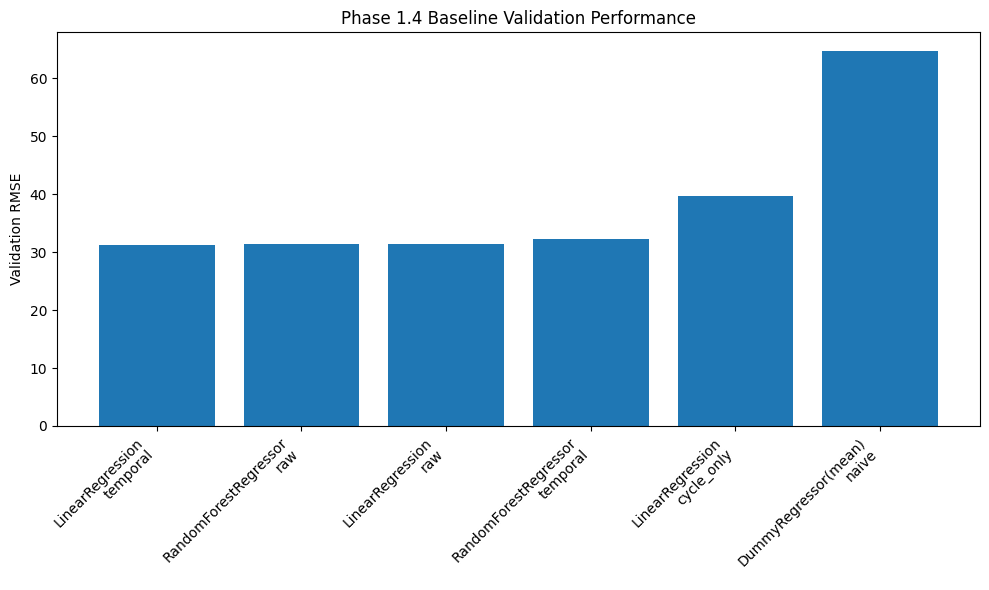

In [75]:
# --- Visualize validation RMSE across all completed baseline experiments ---
#
# What this does:
# Displays the validation performance of every Phase 1.4 baseline fitted so far.
#
# Why this matters:
# The plot provides a high-level performance overview, while the controlled
# comparison tables remain necessary for causal experimental interpretation.
#
# Concept to focus on:
# A leaderboard tells us WHAT scored best. Controlled comparisons help tell us
# WHY performance changed.

results_for_plot = (
    baseline_results
    .sort_values("validation_rmse")
    .copy()
)

labels = (
    results_for_plot["model"]
    + "\n"
    + results_for_plot["representation"]
)

plt.figure(
    figsize=(10, 6)
)

plt.bar(
    labels,
    results_for_plot["validation_rmse"],
)

plt.ylabel(
    "Validation RMSE"
)

plt.title(
    "Phase 1.4 Baseline Validation Performance"
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.tight_layout()
plt.show()

In [76]:
# --- Compare train-validation gaps across baseline models ---
#
# What this does:
# Adds a simple generalization diagnostic to the baseline-results table.
#
# Why this matters:
# Two models can achieve similar validation RMSE while fitting their training
# data very differently.
#
# Concept to focus on:
# Validation performance answers "how well?"
# The train-validation relationship helps answer "how is the model behaving?"

baseline_results_with_gap = (
    baseline_results.copy()
)

baseline_results_with_gap[
    "rmse_generalization_gap"
] = (
    baseline_results_with_gap[
        "validation_rmse"
    ]
    - baseline_results_with_gap[
        "train_rmse"
    ]
)

baseline_results_with_gap.sort_values(
    "validation_rmse"
)

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae,rmse_generalization_gap
4,LinearRegression,temporal,36,41.869866,31.197351,32.078035,24.738745,-10.672516
3,RandomForestRegressor,raw,18,13.792776,31.332492,9.486996,23.724866,17.539716
2,LinearRegression,raw,18,42.002927,31.35452,32.207903,24.89557,-10.648406
5,RandomForestRegressor,temporal,36,11.768613,32.305091,7.811605,23.772653,20.536478
1,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616,-8.395349
0,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967,-3.986213


### Generalization gap is diagnostic, not a standalone ranking metric

A smaller train-validation gap is not automatically better.

For example:

Model A:
- train RMSE = 40
- validation RMSE = 41

Model B:
- train RMSE = 20
- validation RMSE = 24

Model A has the smaller gap, but its prediction performance is much worse.

Therefore:

- validation error remains the primary performance criterion,
- training error provides context,
- and the train-validation gap helps diagnose possible underfitting or
  overfitting.

The gap should not replace validation RMSE as the model-selection metric.

### Interpretation framework

#### Strongest evidence: controlled within-family comparisons

Examples:

- Cycle LinearRegression vs Raw LinearRegression
- Raw LinearRegression vs Temporal LinearRegression
- Raw RandomForest vs Temporal RandomForest

These comparisons hold model family and evaluation population constant while
changing representation.

#### Model-family evidence

Examples:

- Raw LinearRegression vs Raw RandomForest
- Temporal LinearRegression vs Temporal RandomForest

These ask whether a different estimator can extract more predictive value from
the same representation.

#### Overall leaderboard

The full results table identifies which tested baseline achieved the lowest
validation error.

However, overall ranking alone does not identify which individual modeling
choice caused the performance difference.

### Why the lowest Phase 1.4 validation RMSE is not yet the final model

The current results come from one fixed set of held-out validation engines and
from deliberately simple baseline configurations.

Phase 1.5 will test controlled modeling assumptions such as:

- RUL capping,
- engine weighting,
- Sensor 6 ablation,
- richer temporal representations,
- and additional model configurations.

A model that currently has the lowest validation RMSE is therefore the leading
baseline, not the final selected system.

The purpose of Phase 1.4 is to identify which modeling directions have earned
further investigation.

### Modeling implications from controlled comparisons

#### 1. Does cycle count provide useful predictive signal?

Evidence:
Compare DummyRegressor against cycle-only LinearRegression.

Conclusion:
[Fill after inspecting results.]


#### 2. Do current measurements add incremental signal beyond cycle count?

Evidence:
Compare cycle-only LinearRegression against raw LinearRegression.

Conclusion:
[Fill after inspecting results.]


#### 3. Does simple recent history add incremental signal?

Evidence:
Compare raw and temporal models within both LinearRegression and Random Forest.

Conclusion:
[Fill after inspecting results.]


#### 4. Does model flexibility appear important?

Evidence:
Compare LinearRegression and RandomForestRegressor within matched feature
representations.

Conclusion:
[Fill after inspecting results.]


#### 5. What should Phase 1.5 investigate first?

Priority should be determined by the strongest unresolved limitations or
promising improvements observed above rather than by trying every possible
experiment.

In [77]:
# --- Verify the controlled-comparison structure before drawing conclusions ---
#
# What this does:
# Reconfirms that representation comparisons use matched observations and that
# the expected six baseline experiments have been recorded.
#
# Why this matters:
# Task Group 5 is entirely about interpreting performance differences.
# Interpretation is valid only if the underlying comparisons remain controlled.
#
# Concept to focus on:
# Know what changed. Know what stayed fixed. Then interpret the score.

assert X_train_cycle.index.equals(
    X_train_raw.index
)

assert X_train_raw.index.equals(
    X_train_temporal.index
)

assert X_validation_cycle.index.equals(
    X_validation_raw.index
)

assert X_validation_raw.index.equals(
    X_validation_temporal.index
)

assert len(
    baseline_results
) == 6

assert (
    baseline_results[
        "validation_rmse"
    ]
    .notna()
    .all()
)

assert (
    baseline_results[
        "validation_mae"
    ]
    .notna()
    .all()
)

print(
    "Task Group 5 controlled-comparison audit passed."
)

Task Group 5 controlled-comparison audit passed.


### Task Group 5 — Interpretation Questions

1. **What is the difference between an overall model leaderboard and a
   controlled comparison, and why can the leaderboard alone not explain why
   one model achieved lower validation RMSE?**

An overall model leaderboard simply orders different models by the predictive accuracy they achieved. A controlled comparison provides a sequence of different results, with each new part of the sequence answering a different question about accuracy gains or losses. A leaderboard alone can't explain why one model achieved lower validation RMSE because we do not necessarily know what sequence of changes were made moving from one row to the next in a leaderboard. 

2. **What specific question is answered by cycle-only `LinearRegression`
   versus raw `LinearRegression`, and what factors are being deliberately held
   constant in that comparison?**

Does adding information from sensors and operating settings boost a model's predictive capabilities beyond just knowing cycle count? The cycle observations are being held constant in that comparison, i.e., both models draw from the same cycle observations.

*The comparison asks whether the 17 current operating-setting and sensor measurements provide incremental predictive value beyond cycle count. We hold constant the model family, train/validation engine split, engine-cycle observations, targets, and evaluation metrics, while changing the information supplied in X.*

3. **What specific question is answered by raw `LinearRegression` versus raw
   `RandomForestRegressor`, and why should a performance difference there not
   be attributed to the raw feature representation?**

Are there nonlinear relationships in the data that can be captured by a Random Forest model to boost predictive capabilities beyond those of raw features with a linear model? A performance difference there shouldn't be attributed to the raw feature representaion because the Random Forest model is far more flexible. 

*So if it wins, the defensible conclusion is a more flexible nonlinear estimator extracted more predictive signal from the same raw representation.*

*Does a more flexible model make better use of the same raw information?*

4. **Why is validation-RMSE reduction more useful than simply observing that
   training RMSE decreased when moving from raw to temporal features?**

Because validation RMSE is far more useful in evaluating a model over training RMSE because it measures how well a model generalizes to new data. 

*Validation-RMSE reduction tells us whether the richer temporal representation improves predictions on unseen engines. Training RMSE can decrease simply because the additional features give the model more opportunities to fit training-specific structure, so training improvement alone cannot demonstrate useful incremental generalization.*

5. **Why is a smaller train-validation RMSE gap not automatically evidence that
   one model is better than another? Give an example involving a model that
   underfits.**

Because a small train-validation RMSE gap can still happen on a highly inaccurate model. We could have one model with training RMSE at 40 and validation RMSE at 41. Here we have a small gap. But suppose there's a different model with those values being 20 and 28, respectively. Here we have a large gap, but the model is much more accurate. 

6. **If one model currently has the lowest validation RMSE of all six Phase 1.4
   baselines, why should we call it the "best-performing baseline on this
   validation split" rather than the final best model?**

Calling something the best final model requires using the test set for final testing. Here we have used just one particular fold for evaluation, and model results can change significantly moving from one fold to another. Ideally, using multiple folds should be done before moving towards calling something the final best model.

*We should choose the final model using development data only—validation, and eventually, grouped cross-validation.*

*One validation split can be sensitive to which engines happened to land in validation.*

*The lowest Phase 1.4 validation RMSE identifies the leading baseline on this particular held-out engine split, not the final model. We still have additional modeling assumptions to test, and performance on one validation split may depend partly on which engines were selected. Final model selection should be based on development validation evidence, ideally including grouped cross-validation. Only after the design is locked should the official test set be used for final evaluation.*

**Validation/CV selects the model. The official test set evaluates the already-selected model.**

## Task Group 6: Error & Generalization Diagnostics

## Task Group 6: Error & Generalization Diagnostics

### Question

Where do the baseline models make their largest RUL prediction errors, are
those errors systematically associated with particular RUL ranges or engines,
and what do the patterns reveal about model limitations that aggregate RMSE
and MAE alone cannot show?

### Why this matters

Two models can have similar overall RMSE while behaving very differently.

For example, one model might make moderate errors throughout the lifecycle,
while another performs very well for most observations but makes a small
number of extremely large mistakes.

Likewise, a model could perform well near failure but poorly when true RUL is
high.

Aggregate metrics cannot reveal these patterns by themselves.

Phase 1.4 diagnostics will therefore inspect:

- predicted versus actual RUL,
- signed prediction errors,
- error across RUL ranges,
- the largest individual misses,
- variation in performance across validation engines,
- and the relationship between training and validation performance.

These diagnostics are intended to identify modeling limitations and motivate
controlled Phase 1.5 experiments. They do not change the Phase 1.4 evaluation
contract.

In [78]:
# --- Build a common validation-diagnostics table for every baseline model ---
#
# What this does:
# Combines actual RUL, predictions, signed errors, absolute errors, engine IDs,
# and cycle numbers for every completed baseline.
#
# Why this matters:
# Aggregate metrics tell us how much error a model makes overall. A row-level
# diagnostic table lets us investigate WHERE those errors occur.
#
# Concept to focus on:
# Diagnostics are performed after predictions are made. Validation targets are
# legal to use here because we are evaluating model behavior, not constructing X.

validation_prediction_registry = {
    "Dummy / naive": (
        dummy_validation_predictions
    ),
    "Linear / cycle_only": (
        cycle_validation_predictions
    ),
    "Linear / raw": (
        raw_linear_validation_predictions
    ),
    "Forest / raw": (
        raw_forest_validation_predictions
    ),
    "Linear / temporal": (
        temporal_linear_validation_predictions
    ),
    "Forest / temporal": (
        temporal_forest_validation_predictions
    ),
}

diagnostic_frames = []

for model_name, predictions in (
    validation_prediction_registry.items()
):
    frame = build_prediction_frame(
        y_true=y_validation,
        y_pred=predictions,
    )

    frame["model"] = model_name

    frame["unit_no"] = (
        groups_validation
    )

    frame["cycles"] = (
        X_validation_cycle["cycles"]
    )

    frame["squared_error"] = (
        frame["prediction_error"] ** 2
    )

    diagnostic_frames.append(
        frame
    )

validation_diagnostics = pd.concat(
    diagnostic_frames,
    axis=0,
)

validation_diagnostics.head()

,actual_rul,predicted_rul,prediction_error,absolute_error,model,unit_no,cycles,squared_error
4,187,106.483652,-80.516348,80.516348,Dummy / naive,1,5,6482.882217
5,186,106.483652,-79.516348,79.516348,Dummy / naive,1,6,6322.849522
6,185,106.483652,-78.516348,78.516348,Dummy / naive,1,7,6164.816827
7,184,106.483652,-77.516348,77.516348,Dummy / naive,1,8,6008.784132
8,183,106.483652,-76.516348,76.516348,Dummy / naive,1,9,5854.751437


In [79]:
# --- Identify the current leading Phase 1.4 baseline by validation RMSE ---
#
# What this does:
# Recalculates the canonical validation metrics for each baseline and selects
# the model with the lowest RMSE.
#
# Why this matters:
# Detailed diagnostics should focus especially on the current leading baseline,
# while still comparing error patterns across all models.
#
# Concept to focus on:
# The primary metric was defined BEFORE model results were observed.

validation_metric_registry = {
    model_name: calculate_regression_metrics(
        y_validation,
        predictions,
    )
    for model_name, predictions
    in validation_prediction_registry.items()
}

leading_model_name = min(
    validation_metric_registry,
    key=lambda model_name: (
        validation_metric_registry[
            model_name
        ].rmse
    ),
)

leading_metrics = (
    validation_metric_registry[
        leading_model_name
    ]
)

print(
    "Leading Phase 1.4 baseline:",
    leading_model_name,
)

print(
    "Validation metrics:",
    leading_metrics,
)

Leading Phase 1.4 baseline: Linear / temporal
Validation metrics: RegressionMetrics(rmse=31.197350907736663, mae=24.738744815991875)


In [80]:
# --- Isolate row-level diagnostics for the current leading baseline ---
#
# What this does:
# Selects every validation prediction produced by the model with the lowest
# Phase 1.4 validation RMSE.
#
# Why this matters:
# We can now investigate the behavior hidden behind its aggregate score.
#
# Concept to focus on:
# "Best RMSE" does not imply uniform performance across observations.

leading_validation_diagnostics = (
    validation_diagnostics
    .loc[
        validation_diagnostics["model"]
        == leading_model_name
    ]
    .copy()
)

leading_validation_diagnostics.head()

,actual_rul,predicted_rul,prediction_error,absolute_error,model,unit_no,cycles,squared_error
4,187,178.227280,-8.772720,8.772720,Linear / temporal,1,5,76.960610
5,186,183.274309,-2.725691,2.725691,Linear / temporal,1,6,7.429390
6,185,183.428119,-1.571881,1.571881,Linear / temporal,1,7,2.470811
7,184,184.099876,0.099876,0.099876,Linear / temporal,1,8,0.009975
8,183,184.028100,1.028100,1.028100,Linear / temporal,1,9,1.056989


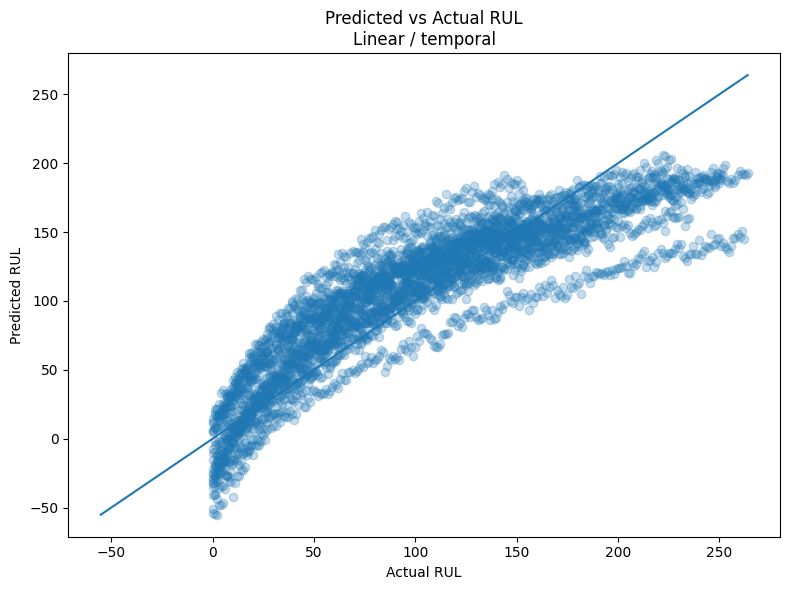

In [81]:
# --- Compare predicted and actual RUL for the leading baseline ---
#
# What this does:
# Plots every held-out prediction against its true RUL and adds the perfect
# prediction line.
#
# Why this matters:
# This reveals whether errors are distributed evenly or whether predictions
# systematically compress, overestimate, or underestimate parts of the RUL
# range.
#
# Concept to focus on:
# Distance from the diagonal represents prediction error.

actual = (
    leading_validation_diagnostics[
        "actual_rul"
    ]
)

predicted = (
    leading_validation_diagnostics[
        "predicted_rul"
    ]
)

plot_min = min(
    actual.min(),
    predicted.min(),
)

plot_max = max(
    actual.max(),
    predicted.max(),
)

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    actual,
    predicted,
    alpha=0.25,
)

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
)

plt.xlabel(
    "Actual RUL"
)

plt.ylabel(
    "Predicted RUL"
)

plt.title(
    f"Predicted vs Actual RUL\n{leading_model_name}"
)

plt.tight_layout()
plt.show()

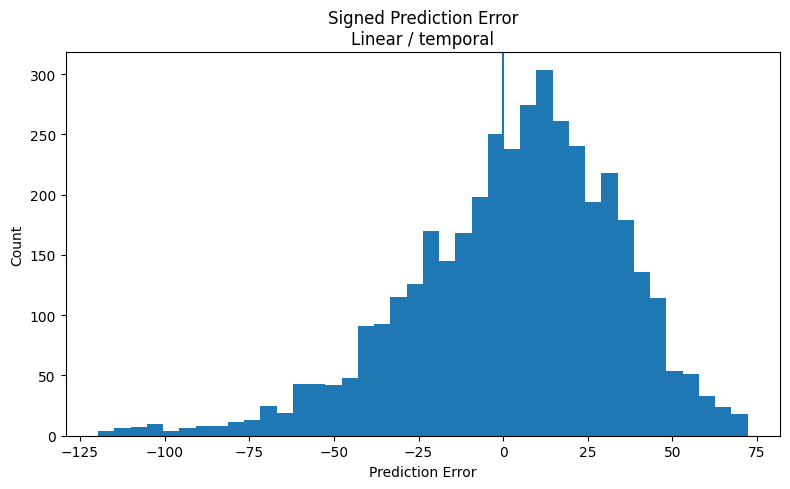

In [82]:
# --- Inspect the distribution of signed validation errors ---
#
# What this does:
# Shows whether prediction errors are centered around zero or systematically
# skew toward RUL overprediction or underprediction.
#
# Why this matters:
# MAE and RMSE discard error direction. Signed errors reveal systematic bias.
#
# Concept to focus on:
# A model can have reasonable MAE while consistently predicting too high or
# too low in particular regions.

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    leading_validation_diagnostics[
        "prediction_error"
    ],
    bins=40,
)

plt.axvline(
    0,
)

plt.xlabel(
    "Prediction Error"
)

plt.ylabel(
    "Count"
)

plt.title(
    f"Signed Prediction Error\n{leading_model_name}"
)

plt.tight_layout()
plt.show()

In [83]:
# --- Quantify overall error direction for the leading baseline ---
#
# What this does:
# Calculates the mean and median signed error and the proportions of
# overpredictions and underpredictions.
#
# Why this matters:
# These values help distinguish random-looking error from systematic bias.

mean_signed_error = (
    leading_validation_diagnostics[
        "prediction_error"
    ]
    .mean()
)

median_signed_error = (
    leading_validation_diagnostics[
        "prediction_error"
    ]
    .median()
)

overprediction_fraction = (
    (
        leading_validation_diagnostics[
            "prediction_error"
        ]
        > 0
    )
    .mean()
)

underprediction_fraction = (
    (
        leading_validation_diagnostics[
            "prediction_error"
        ]
        < 0
    )
    .mean()
)

print(
    "Mean signed error:",
    mean_signed_error,
)

print(
    "Median signed error:",
    median_signed_error,
)

print(
    "Overprediction fraction:",
    overprediction_fraction,
)

print(
    "Underprediction fraction:",
    underprediction_fraction,
)

Mean signed error: 3.189642656346476
Median signed error: 6.961000408864493
Overprediction fraction: 0.5889724310776943
Underprediction fraction: 0.41102756892230574


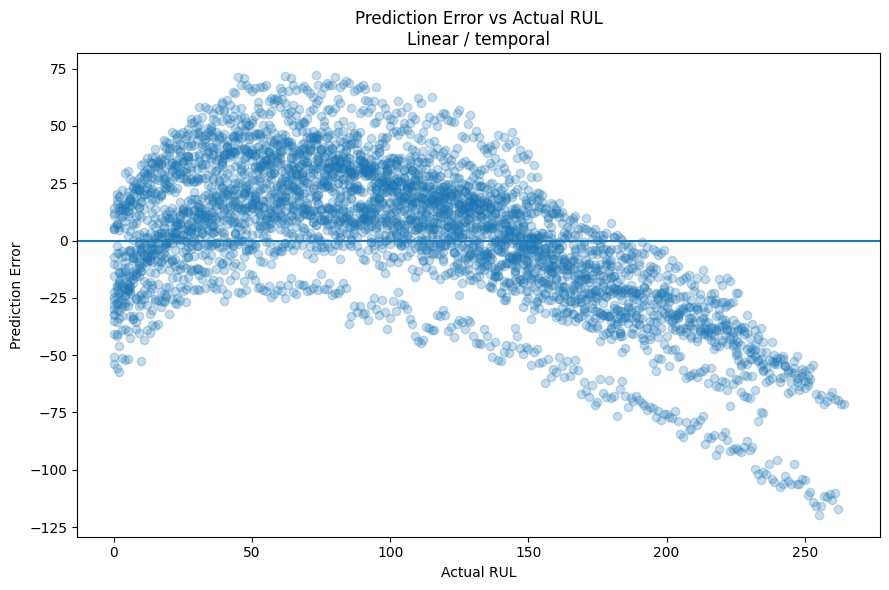

In [84]:
# --- Inspect whether prediction behavior changes across the RUL range ---
#
# What this does:
# Plots signed prediction error against actual RUL for every validation
# observation.
#
# Why this matters:
# A model may behave differently near failure than early in an engine's
# observed lifecycle.
#
# Concept to focus on:
# Aggregate RMSE can hide target-dependent error patterns.

plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    leading_validation_diagnostics[
        "actual_rul"
    ],
    leading_validation_diagnostics[
        "prediction_error"
    ],
    alpha=0.25,
)

plt.axhline(
    0,
)

plt.xlabel(
    "Actual RUL"
)

plt.ylabel(
    "Prediction Error"
)

plt.title(
    f"Prediction Error vs Actual RUL\n{leading_model_name}"
)

plt.tight_layout()
plt.show()

In [85]:
# --- Create target-based RUL bands for POST-HOC validation diagnostics ---
#
# What this does:
# Groups validation observations according to their true RUL so model error can
# be compared across broad prediction horizons.
#
# Why this matters:
# Overall metrics may conceal much worse performance in particular RUL regions.
#
# Concept to focus on:
# Using y_validation to evaluate errors AFTER prediction is legal.
# Feeding an RUL-derived band into X would be target leakage.

validation_diagnostics[
    "rul_band"
] = pd.cut(
    validation_diagnostics[
        "actual_rul"
    ],
    bins=[
        -1,
        30,
        60,
        120,
        np.inf,
    ],
    labels=[
        "0-30",
        "31-60",
        "61-120",
        "121+",
    ],
)

In [86]:
# --- Measure RMSE, MAE, and signed bias within each RUL band ---
#
# What this does:
# Breaks each model's validation error into broad remaining-life regions.
#
# Why this matters:
# This can reveal that two models with similar overall RMSE have very different
# strengths and weaknesses across the lifecycle.
#
# Concept to focus on:
# Target-stratified diagnostics tell us WHERE error occurs.

rul_band_summary = (
    validation_diagnostics
    .groupby(
        [
            "model",
            "rul_band",
        ],
        observed=True,
    )
    .agg(
        n_rows=(
            "actual_rul",
            "size",
        ),
        mae=(
            "absolute_error",
            "mean",
        ),
        rmse=(
            "squared_error",
            lambda values: float(
                np.sqrt(
                    values.mean()
                )
            ),
        ),
        mean_signed_error=(
            "prediction_error",
            "mean",
        ),
    )
    .reset_index()
)

rul_band_summary

,model,rul_band,n_rows,mae,rmse,mean_signed_error
0,Dummy / naive,0-30,620,91.483652,91.919849,91.483652
1,Dummy / naive,31-60,600,60.983652,61.594826,60.983652
2,Dummy / naive,61-120,1200,19.257948,23.566795,15.983652
3,Dummy / naive,121+,1570,64.254564,73.633134,-64.254564
4,Forest / raw,0-30,620,5.881855,8.531072,4.128048
5,Forest / raw,31-60,600,16.896467,22.480455,12.904367
6,Forest / raw,61-120,1200,28.629083,35.258881,21.182233
7,Forest / raw,121+,1570,29.632283,36.371324,-9.080341
8,Forest / temporal,0-30,620,4.606242,7.141800,2.710516
9,Forest / temporal,31-60,600,15.807383,21.262070,11.329433


In [87]:
# --- Inspect lifecycle-region performance for the leading baseline ---
#
# What this does:
# Filters the RUL-band diagnostic table to the model currently leading Phase
# 1.4 validation performance.
#
# Why this matters:
# We want to know whether its strong overall score hides a major weakness in a
# particular prediction horizon.

leading_rul_band_summary = (
    rul_band_summary
    .loc[
        rul_band_summary["model"]
        == leading_model_name
    ]
    .copy()
)

leading_rul_band_summary

,model,rul_band,n_rows,mae,rmse,mean_signed_error
20,Linear / temporal,0-30,620,19.210763,23.234476,3.837769
21,Linear / temporal,31-60,600,26.229439,31.389979,23.172960
22,Linear / temporal,61-120,1200,24.385621,29.223853,20.781202
23,Linear / temporal,121+,1570,26.621981,35.085210,-18.149020


In [88]:
# --- Compare model performance within each true-RUL region ---
#
# What this does:
# Pivots the diagnostic results so each model's RMSE can be compared across the
# same RUL bands.
#
# Why this matters:
# One model may win overall while another is stronger in a specific lifecycle
# region.

rul_band_rmse_table = (
    rul_band_summary
    .pivot(
        index="rul_band",
        columns="model",
        values="rmse",
    )
)

rul_band_rmse_table

model,Dummy / naive,Forest / raw,Forest / temporal,Linear / cycle_only,Linear / raw,Linear / temporal
rul_band,,,,,,
0-30,91.919849,8.531072,7.141800,47.107697,23.514928,23.234476
31-60,61.594826,22.480455,21.262070,40.704998,31.435263,31.389979
61-120,23.566795,35.258881,36.516045,33.542971,29.421116,29.223853
121+,73.633134,36.371324,37.949555,40.475597,35.225702,35.085210


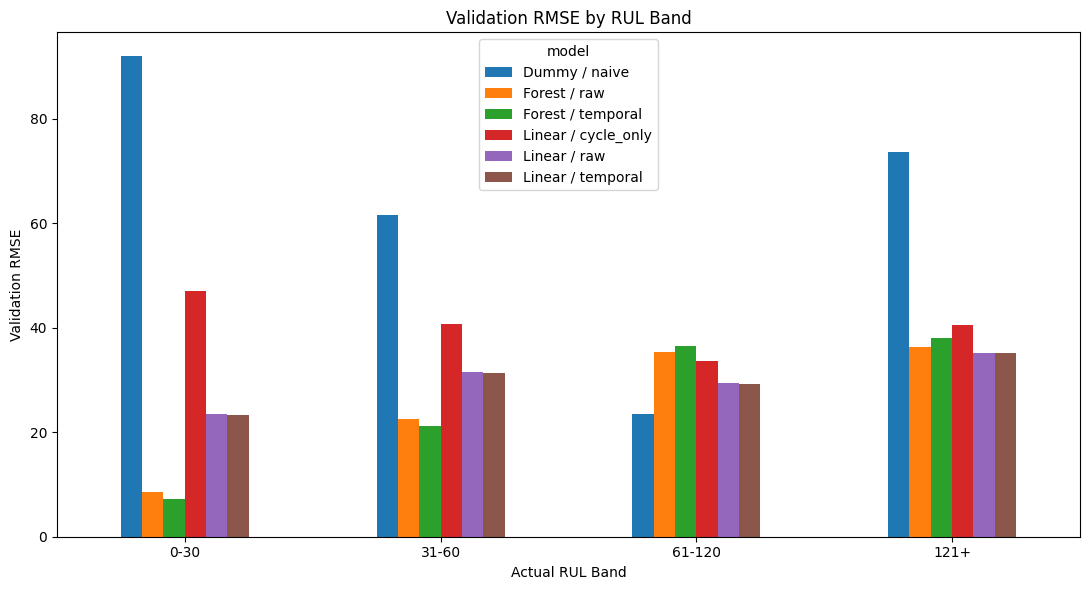

In [89]:
# --- Visualize RMSE by RUL band across baseline models ---
#
# What this does:
# Turns the RUL-band table into a grouped bar chart.
#
# Why this matters:
# Differences in model behavior across lifecycle regions are often easier to
# recognize visually than in a large table.

rul_band_rmse_table.plot(
    kind="bar",
    figsize=(11, 6),
)

plt.ylabel(
    "Validation RMSE"
)

plt.xlabel(
    "Actual RUL Band"
)

plt.title(
    "Validation RMSE by RUL Band"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()
plt.show()

In [90]:
# --- Inspect the largest absolute errors made by the leading baseline ---
#
# What this does:
# Finds the validation observations with the most severe prediction misses.
#
# Why this matters:
# A handful of extreme mistakes may explain why RMSE is substantially larger
# than MAE.
#
# Concept to focus on:
# Large-error examples can generate hypotheses, but a few examples should not
# be used to invent broad conclusions without checking aggregate patterns.

largest_misses = (
    leading_validation_diagnostics
    .sort_values(
        "absolute_error",
        ascending=False,
    )
    [
        [
            "unit_no",
            "cycles",
            "actual_rul",
            "predicted_rul",
            "prediction_error",
            "absolute_error",
        ]
    ]
    .head(15)
)

largest_misses

,unit_no,cycles,actual_rul,predicted_rul,prediction_error,absolute_error
16896,84,12,255,135.350657,-119.649343,119.649343
16889,84,5,262,144.712672,-117.287328,117.287328
16897,84,13,254,137.976579,-116.023421,116.023421
16895,84,11,256,140.058698,-115.941302,115.941302
16898,84,14,253,139.037017,-113.962983,113.962983
16891,84,7,260,146.729877,-113.270123,113.270123
16893,84,9,258,145.959920,-112.040080,112.040080
16894,84,10,257,145.666165,-111.333835,111.333835
16900,84,16,251,140.080621,-110.919379,110.919379
16892,84,8,259,148.432297,-110.567703,110.567703


In [91]:
# --- Calculate error separately for each held-out validation engine ---
#
# What this does:
# Measures the leading model's RMSE, MAE, bias, and observation count for each
# of the 20 unseen validation engines.
#
# Why this matters:
# A strong aggregate score can hide engines on which the model performs poorly.
#
# Concept to focus on:
# Generalization is not only "does this work on validation rows?"
# We also care whether performance transfers consistently across unseen engines.

engine_diagnostics = (
    leading_validation_diagnostics
    .groupby(
        "unit_no"
    )
    .agg(
        n_rows=(
            "actual_rul",
            "size",
        ),
        rmse=(
            "squared_error",
            lambda values: float(
                np.sqrt(
                    values.mean()
                )
            ),
        ),
        mae=(
            "absolute_error",
            "mean",
        ),
        mean_signed_error=(
            "prediction_error",
            "mean",
        ),
    )
    .sort_values(
        "rmse",
        ascending=False,
    )
)

engine_diagnostics

,n_rows,rmse,mae,mean_signed_error
unit_no,,,,
84,263,59.469756,51.311942,-51.311942
45,154,53.423734,50.992127,50.864671
74,162,43.413134,40.971741,40.971741
77,150,36.125293,33.877110,33.877110
91,131,33.522383,31.841437,31.841437
5,265,31.996768,24.192319,-22.746639
1,188,30.933670,27.552918,27.229869
81,236,30.773376,22.407710,-21.577567
13,159,27.615132,24.611489,23.064076


In [92]:
# --- Summarize variation in validation performance across unseen engines ---

print(
    "Best engine RMSE:",
    engine_diagnostics["rmse"].min(),
)

print(
    "Median engine RMSE:",
    engine_diagnostics["rmse"].median(),
)

print(
    "Worst engine RMSE:",
    engine_diagnostics["rmse"].max(),
)

Best engine RMSE: 16.010151327090277
Median engine RMSE: 26.377908574005406
Worst engine RMSE: 59.469755881691725


### Row-level evaluation and engine-level diagnostics answer different questions

The primary Phase 1.4 RMSE is calculated across prediction rows.

Therefore, an engine with more eligible cycles contributes more observations
to the aggregate metric than a shorter engine.

The per-engine diagnostic table does not replace that evaluation contract.

Instead, it asks whether model performance is reasonably consistent across the
held-out engines.

Later experiments may explicitly investigate equal-engine weighting during
training.

That would be a change to the modeling procedure and should be evaluated as a
controlled experiment rather than silently introduced during diagnostics.

In [93]:
# --- Revisit fitting behavior alongside validation performance ---
#
# What this does:
# Shows training error, validation error, and their gap for every baseline.
#
# Why this matters:
# Error-pattern diagnostics should be interpreted together with how aggressively
# each model fits the development-training population.

baseline_results_with_gap[
    [
        "model",
        "representation",
        "train_rmse",
        "validation_rmse",
        "rmse_generalization_gap",
    ]
].sort_values(
    "validation_rmse"
)

,model,representation,train_rmse,validation_rmse,rmse_generalization_gap
4,LinearRegression,temporal,41.869866,31.197351,-10.672516
3,RandomForestRegressor,raw,13.792776,31.332492,17.539716
2,LinearRegression,raw,42.002927,31.35452,-10.648406
5,RandomForestRegressor,temporal,11.768613,32.305091,20.536478
1,LinearRegression,cycle_only,48.106868,39.711519,-8.395349
0,DummyRegressor(mean),naive,68.669077,64.682864,-3.986213


### Diagnostic findings and Phase 1.5 hypotheses

#### 1. Error across RUL

Question:
Does prediction error become substantially worse in particular RUL regions?

Observed evidence:
[Fill after inspecting the RUL-band diagnostics.]

Possible Phase 1.5 implication:
If high-RUL prediction is especially poor, test capped RUL as a controlled
target-design experiment.


#### 2. Large prediction errors

Question:
Are severe RMSE-driving mistakes concentrated in a recognizable region or
pattern?

Observed evidence:
[Fill after inspecting the largest misses.]

Possible Phase 1.5 implication:
Use the observed pattern to prioritize representation or model experiments
rather than treating all errors as equivalent.


#### 3. Generalization across engines

Question:
Is validation performance reasonably consistent across the 20 unseen engines?

Observed evidence:
[Fill after inspecting per-engine metrics.]

Possible Phase 1.5 implication:
Large engine-to-engine variability may justify more robust grouped
cross-validation before trusting small performance differences.


#### 4. Training versus validation behavior

Question:
Which models appear to underfit or overfit relative to the alternatives?

Observed evidence:
[Fill after inspecting training and validation errors.]

Possible Phase 1.5 implication:
Use this evidence when deciding whether additional model capacity,
regularization, or hyperparameter control deserves investigation.

### Avoid reacting to individual errors by changing the model immediately

Diagnostics can make it tempting to inspect a difficult validation observation
and modify the pipeline specifically to fix it.

Repeatedly tailoring the model to individual validation errors risks
overfitting the validation set itself.

Instead:

1. identify a broader, plausible pattern,
2. formulate a modeling hypothesis,
3. define a controlled experiment,
4. evaluate the experiment under the same validation contract.

Validation data may guide development, but it should not encourage
observation-by-observation patching.

### The official test set is still not part of these diagnostics

All error diagnostics in this task group use the held-out development
validation engines.

We do not inspect:

- official test prediction errors,
- official test RUL bands,
- worst official test engines,
- or official test residual plots.

Doing so would expose the final test outcomes during model development and
allow them to influence Phase 1.5 decisions.

The official test labels remain reserved for final evaluation.

In [94]:
# --- Verify the Phase 1.4 diagnostic dataset before drawing conclusions ---
#
# What this does:
# Confirms that each model contributes exactly one validation prediction per
# canonical observation and that diagnostic metadata remains aligned.
#
# Why this matters:
# Error analysis is only trustworthy if predictions, targets, cycles, and
# engine identities refer to the same observations.
#
# Concept to focus on:
# Diagnostics inherit the same alignment requirements as model evaluation.

expected_rows_per_model = len(
    y_validation
)

diagnostic_counts = (
    validation_diagnostics
    .groupby("model")
    .size()
)

assert (
    diagnostic_counts
    == expected_rows_per_model
).all()

assert (
    leading_validation_diagnostics[
        "unit_no"
    ]
    .nunique()
    == 20
)

assert (
    leading_validation_diagnostics[
        "actual_rul"
    ]
    .notna()
    .all()
)

assert (
    leading_validation_diagnostics[
        "predicted_rul"
    ]
    .notna()
    .all()
)

assert np.isfinite(
    leading_validation_diagnostics[
        "predicted_rul"
    ]
).all()

print(
    "Task Group 6 error-diagnostic audit passed."
)

Task Group 6 error-diagnostic audit passed.


### Task Group 6 — Interpretation Questions

1. **Why can two models with similar overall validation RMSE still have very
   different practical error behavior, and what kinds of patterns can
   row-level diagnostics reveal that RMSE alone cannot?**

Because errors can have different frequencies and magnitudes. It's possible for two models to have equal RMSE. Picture a situation where one model makes a high number of small errors and one model makes a low number of large errors. 

2. **Using our signed-error convention, what would systematically negative
   errors at high true RUL mean? Why could the overall mean signed error still
   be near zero even if the model makes large mistakes?**

That would mean the model is underestimating the engine's RUL when the engine has a high number of cycles remaining in its true lifecycle. It could be zero as a result of large positive mistakes being balanced out by large negative mistakes. Calculating the mean is done as a summation and it's possible for two large errors to sum to zero.

3. **Why is it legal to construct `rul_band` from `y_validation` for post-hoc
   error analysis, while using an RUL-derived band as a predictor in `X` would
   be target leakage?**

In post-hoc error analysis, there is no need to guard the model from being given future information because the evaluation has already been done. If an RUL-derived band is included as a predictor in `X`, on the other hand, then a model can infer how much RUL there is as a result of knowing if it's in a high or a low band. That is a form of leakage because the model has access to information from the future. 

*The model is never given `rul_band` at all.*

*Validation labels are legal for scoring and post-hoc diagnostics. They are illegal as predictive inputs.*

4. **If validation RMSE is much worse for the `121+` RUL band than for lower-RUL
   bands, what modeling experiment might that motivate in Phase 1.5, and why
   would the diagnostic result not by itself prove that experiment will help?**

Lifecycle capping is an experiment that could be done in Phaase 1.5. The diagnostic result would not prove that the experiment will help because no model training has taken place under the lifecycle capping. (I'm unsure of how to confidently answer this one.)

*Maybe forcing the model to predict exact long-horizon RUL is adding difficult/noisy target variation that doesn't help the degradation problem.*

*Poor performance in the `121+` region would motivate testing capped RUL because exact long-horizon remaining life may be difficult to identify from observable engine state. However, the diagnostic only identifies a possible weakness and it does not show that changing the target will solve it. The capped RUL model must be retrained and evaluated as a controlled experiment.*

5. **Why can overall row-level validation RMSE hide poor generalization to a
   small number of engines, and why do per-engine diagnostics complement rather
   than replace the primary evaluation metric?**

Because a small number of engines can probabilistically wind up being easy to make predictions about, it's only when applying the model to a large number of unseen engines that we can get a good gauge of generailizability. Per-engine diagnostic cannot replace the primary evaluation metric because we need to gauge the accuracy of the model across a fleet, not just at the individual level. (I'm also unsure of how to confidently answer this one.)

*Overall row-level RMSE aggregates all validation observations, so poor performance on a few engines can be diluted by good performance on many other rows, and longer engines contribute more observations than shorter engines. Per-engine diagnostics reveal whether the model generalizes consistently across individual unseen engines. They complement rather than replace the primary metric because our established evaluation contract measures prediction error across all validation rows.*

6. **Why would repeatedly modifying the model to fix individual validation
   errors risk overfitting the validation set even though the model is never
   directly fitted on `y_validation`?**

Because that would make the model specialize in predictions for a finite number of engines. Upon being applied to engines not in the fleet that it specialized in fitting it's likely that RMSE would increase. (Again, not super sure of how to confidently answer this one.)

*Repeatedly optimizing around those particular engines can make the development process specialize to them.*

*Even if `model.fit()` never receives validation targets, repeated model modifications based on validation errors use those targets indirectly as an optimization signal. Over many iterations, feature engineering and model selection decisions can become specialized to the particular validation engines, causing validation performance to become overly optimistic relative to truly unseen data.*

**RUL-band diagnostics generate a hypothesis for capping. Retraining and validation test that hypothesis.**

**Row-level RMSE measures fleet-wide prediction rows. Per-engine diagnostics tell us whether that aggregate performance is consistent across unseen engines.**

**Validation overfitting can happen through the developer's repeated decisions even when `model.fit()` never sees `y_validation`.**

## Task Group 7: Baseline Conclusions & Phase 1.5 Experiment Priorities

## Task Group 7: Baseline Conclusions & Phase 1.5 Experiment Priorities

### Question

What conclusions are supported by the Phase 1.4 baseline experiments, what
limitations remain unresolved, and which controlled experiments should receive
priority in Phase 1.5?

### Why this matters

The goal of Phase 1.4 was not to find the final model.

It was to establish credible reference performance and answer a sequence of
modeling questions:

1. Does cycle count contain predictive signal?
2. Do current sensor and operating-setting measurements add information beyond
   cycle count?
3. Does recent temporal history add information beyond current state?
4. Does a more flexible nonlinear model exploit the available information
   better?
5. Where do the resulting models make their largest errors?

Phase 1.5 should now be driven by evidence from these experiments rather than
by trying arbitrary combinations until validation RMSE decreases.

In [95]:
# --- Display the final Phase 1.4 baseline leaderboard ---
#
# What this does:
# Ranks all six completed baseline experiments using the primary validation
# metric declared before modeling began.
#
# Why this matters:
# This identifies the current leading baseline, but does not by itself explain
# why performance differed between models.
#
# Concept to focus on:
# Leaderboard = performance ranking.
# Controlled comparisons = experimental interpretation.

phase_14_leaderboard = (
    baseline_results_with_gap
    .sort_values(
        "validation_rmse"
    )
    .reset_index(
        drop=True
    )
)

phase_14_leaderboard

,model,representation,n_features,train_rmse,validation_rmse,train_mae,validation_mae,rmse_generalization_gap
0,LinearRegression,temporal,36,41.869866,31.197351,32.078035,24.738745,-10.672516
1,RandomForestRegressor,raw,18,13.792776,31.332492,9.486996,23.724866,17.539716
2,LinearRegression,raw,18,42.002927,31.35452,32.207903,24.89557,-10.648406
3,RandomForestRegressor,temporal,36,11.768613,32.305091,7.811605,23.772653,20.536478
4,LinearRegression,cycle_only,1,48.106868,39.711519,37.116964,33.595616,-8.395349
5,DummyRegressor(mean),naive,0,68.669077,64.682864,56.37831,54.460967,-3.986213


In [96]:
# --- Identify the strongest baseline under the Phase 1.4 evaluation contract ---
#
# What this does:
# Selects the experiment with the lowest validation RMSE.
#
# Why this matters:
# Phase 1.5 needs a reference model against which controlled changes can be
# compared.
#
# Concept to focus on:
# This is the leading BASELINE on one fixed validation split, not the final
# selected model.

leading_baseline = (
    phase_14_leaderboard
    .iloc[0]
)

print(
    "Leading baseline:"
)

print(
    leading_baseline[
        [
            "model",
            "representation",
            "validation_rmse",
            "validation_mae",
            "rmse_generalization_gap",
        ]
    ]
)

Leading baseline:
model                      LinearRegression
representation                     temporal
validation_rmse                   31.197351
validation_mae                    24.738745
rmse_generalization_gap          -10.672516
Name: 0, dtype: object


In [97]:
# --- Re-display the experiments that support representation conclusions ---
#
# What this does:
# Collects the most interpretable Phase 1.4 comparisons in one place.
#
# Why this matters:
# Conclusions about feature value should be based primarily on comparisons
# where model family and evaluation population were held constant.

controlled_comparisons

,comparison,changed,question,rmse_reduction
0,Dummy → Cycle Linear,use of cycle information,Does observable engine age improve over a cons...,24.971345
1,Cycle Linear → Raw Linear,feature representation,Do current measurements add value beyond cycle...,8.356999
2,Raw Linear → Temporal Linear,feature representation,Does recent history add value beyond current s...,0.157169
3,Raw Linear → Raw Forest,model family,Can a more flexible model exploit the same raw...,0.022028
4,Raw Forest → Temporal Forest,feature representation,Does recent history add value within Random Fo...,-0.972599


In [98]:
# --- Build a structured summary of the central Phase 1.4 modeling questions ---
#
# What this does:
# Places the relevant validation scores and RMSE changes beside each modeling
# question.
#
# Why this matters:
# A good conclusion should be traceable to the specific comparison that
# generated the evidence.
#
# Concept to focus on:
# Evidence first. Interpretation second.

phase_14_questions = pd.DataFrame(
    [
        {
            "question": (
                "Does cycle count add predictive value?"
            ),
            "comparison": (
                "Dummy → Cycle Linear"
            ),
            "rmse_before": (
                dummy_validation_metrics.rmse
            ),
            "rmse_after": (
                cycle_validation_metrics.rmse
            ),
            "rmse_reduction": (
                dummy_validation_metrics.rmse
                - cycle_validation_metrics.rmse
            ),
        },
        {
            "question": (
                "Do current measurements add value beyond cycle count?"
            ),
            "comparison": (
                "Cycle Linear → Raw Linear"
            ),
            "rmse_before": (
                cycle_validation_metrics.rmse
            ),
            "rmse_after": (
                raw_linear_validation_metrics.rmse
            ),
            "rmse_reduction": (
                cycle_validation_metrics.rmse
                - raw_linear_validation_metrics.rmse
            ),
        },
        {
            "question": (
                "Does recent history help LinearRegression?"
            ),
            "comparison": (
                "Raw Linear → Temporal Linear"
            ),
            "rmse_before": (
                raw_linear_validation_metrics.rmse
            ),
            "rmse_after": (
                temporal_linear_validation_metrics.rmse
            ),
            "rmse_reduction": (
                raw_linear_validation_metrics.rmse
                - temporal_linear_validation_metrics.rmse
            ),
        },
        {
            "question": (
                "Does recent history help Random Forest?"
            ),
            "comparison": (
                "Raw Forest → Temporal Forest"
            ),
            "rmse_before": (
                raw_forest_validation_metrics.rmse
            ),
            "rmse_after": (
                temporal_forest_validation_metrics.rmse
            ),
            "rmse_reduction": (
                raw_forest_validation_metrics.rmse
                - temporal_forest_validation_metrics.rmse
            ),
        },
        {
            "question": (
                "Does nonlinear model flexibility help on raw features?"
            ),
            "comparison": (
                "Raw Linear → Raw Forest"
            ),
            "rmse_before": (
                raw_linear_validation_metrics.rmse
            ),
            "rmse_after": (
                raw_forest_validation_metrics.rmse
            ),
            "rmse_reduction": (
                raw_linear_validation_metrics.rmse
                - raw_forest_validation_metrics.rmse
            ),
        },
    ]
)

phase_14_questions

,question,comparison,rmse_before,rmse_after,rmse_reduction
0,Does cycle count add predictive value?,Dummy → Cycle Linear,64.682864,39.711519,24.971345
1,Do current measurements add value beyond cycle...,Cycle Linear → Raw Linear,39.711519,31.354520,8.356999
2,Does recent history help LinearRegression?,Raw Linear → Temporal Linear,31.354520,31.197351,0.157169
3,Does recent history help Random Forest?,Raw Forest → Temporal Forest,31.332492,32.305091,-0.972599
4,Does nonlinear model flexibility help on raw f...,Raw Linear → Raw Forest,31.354520,31.332492,0.022028


### Conclusion-strength rule

Phase 1.4 conclusions should describe exactly what the experiments support.

Good:

"The raw representation reduced validation RMSE relative to cycle-only
LinearRegression on the fixed held-out engine split."

Too strong:

"The sensors explain engine failure."

Good:

"The tested temporal representation improved validation performance under
Random Forest."

Too strong:

"Temporal features are necessary for RUL prediction."

Good:

"The baseline Random Forest generalized better than LinearRegression using the
same raw representation."

Too strong:

"RUL is fundamentally nonlinear."

The strength of the conclusion should remain proportional to the experiment
that produced it.

### Phase 1.4 Baseline Findings

#### 1. Observable engine age

Evidence:
Dummy validation RMSE = [fill]
Cycle-only LinearRegression validation RMSE = [fill]

Interpretation:
[State whether cycle count demonstrated meaningful predictive value relative to
the constant benchmark.]


#### 2. Current multivariate engine state

Evidence:
Cycle-only LinearRegression validation RMSE = [fill]
Raw LinearRegression validation RMSE = [fill]

Interpretation:
[State whether the 2 varying operating settings and 15 nonconstant sensors
demonstrated incremental predictive value beyond cycle count.]


#### 3. Recent temporal history

Evidence:

Raw LinearRegression validation RMSE = [fill]
Temporal LinearRegression validation RMSE = [fill]

Raw Random Forest validation RMSE = [fill]
Temporal Random Forest validation RMSE = [fill]

Interpretation:
[State whether lag-1, difference-1, and rolling-mean-5 features demonstrated
incremental value and whether the result was consistent across model families.]


#### 4. Model-family flexibility

Evidence:
Raw LinearRegression validation RMSE = [fill]
Raw Random Forest validation RMSE = [fill]

Interpretation:
[State whether the more flexible nonlinear baseline extracted more predictive
signal from the same raw representation.]


#### 5. Generalization behavior

Evidence:
[Summarize train-validation gaps and per-engine variability.]

Interpretation:
[State which models appear to underfit, overfit, or generalize relatively well,
using cautious language.]


#### 6. Error structure

Evidence:
[Summarize RUL-band RMSE, signed-error patterns, and largest-error patterns.]

Interpretation:
[State which regions of the prediction problem appear most difficult.]

### Findings versus Phase 1.5 hypotheses

A Phase 1.4 finding describes what happened in an experiment already run.

Example:

"Validation RMSE was much higher in the 121+ RUL region than in the 0-30 RUL
region."

A Phase 1.5 hypothesis proposes an explanation or intervention.

Example:

"Capping high RUL values may improve learnability by avoiding the need to
distinguish exact long-horizon remaining life."

The finding is evidence.

The hypothesis still requires a new controlled experiment.

### Candidate Phase 1.5 Experiments

#### A. RUL capping

Question:
Does replacing exact high-RUL targets with a capped target improve validation
performance?

Motivation:
High-RUL states may be intrinsically harder to distinguish precisely.

Candidate values established during EDA:
- 100
- 125
- 150


#### B. Equal-engine training weights

Question:
Does giving each engine approximately equal total influence during fitting
improve generalization?

Motivation:
Ordinary row-level fitting gives longer-lived engines more total training
weight because they contribute more rows.


#### C. Sensor 6 ablation

Question:
Does removing the near-constant Sensor 6 improve, worsen, or leave performance
unchanged?

Motivation:
Sensor 6 survived the zero-variance screen but showed very little variation.


#### D. Expanded temporal representation

Question:
Do richer causal history summaries improve prediction beyond the simple
lag-1 / difference-1 / rolling-mean-5 representation?

Possible candidates:
- longer lags,
- additional rolling windows,
- rolling standard deviation,
- rolling slope,
- longer-horizon change features.


#### E. Model capacity / regularization

Question:
Can model configuration improve generalization without simply fitting training
engines more aggressively?

Possible directions:
- regularized linear models,
- controlled Random Forest parameters,
- other appropriate nonlinear tabular models.

### One-factor-at-a-time experimental discipline

Phase 1.5 should avoid constructing one giant "improved" pipeline that changes:

- RUL cap,
- sample weighting,
- sensor subset,
- temporal features,
- model family,
- and hyperparameters

all at once.

If such a pipeline improves, we would not know which change was responsible.

Instead, important modeling assumptions should first be tested as controlled
experiments against a stable reference baseline.

Once useful changes have demonstrated value individually, selected changes can
later be combined and tested together.

### Phase 1.5 Priority Logic

#### Prioritize RUL capping if:

- high-RUL bands have substantially worse RMSE,
- prediction errors show systematic compression or underprediction at high RUL,
- and exact early-life RUL appears difficult to identify from current state.

#### Prioritize richer temporal features if:

- simple temporal features improved either baseline model,
- or diagnostics suggest current-state models miss degradation dynamics that
  recent history might represent.

#### Prioritize model-capacity / regularization experiments if:

- LinearRegression appears to underfit,
- Random Forest substantially outperforms it,
- or Random Forest shows a large train-validation gap that suggests its
  capacity needs control.

#### Prioritize equal-engine weighting if:

- performance varies substantially across engines,
- longer engines disproportionately influence training,
- or row-level performance appears strong while engine-level consistency is
  weak.

#### Prioritize Sensor 6 ablation as a cheap controlled experiment regardless:

- it is near-constant,
- the change is simple,
- and its contribution can be tested directly rather than assumed.

### Priority order is evidence-dependent

The default Phase 1.5 order is not immutable.

For example:

If temporal Random Forest dramatically outperforms raw Random Forest:
→ richer temporal engineering becomes a higher priority.

If temporal features provide essentially no improvement:
→ temporal expansion should receive lower priority unless diagnostics provide a
strong reason to revisit it.

If the 121+ RUL region dominates prediction error:
→ RUL capping becomes especially compelling.

If Random Forest has extremely low training error but weak validation
performance:
→ regularization / capacity control becomes more urgent.

Experiment priority should follow the strongest evidence rather than a fixed
checklist.

### Phase 1.5 Controlled-Experiment Contract

Unless an experiment explicitly changes one of these components, preserve:

- the engine-grouped validation design,
- the same development population,
- causal and engine-bounded temporal construction,
- test-label isolation,
- the declared RMSE / MAE evaluation functions,
- row alignment,
- feature leakage protections,
- fold-safe learned preprocessing.

Each experiment should explicitly document:

1. Hypothesis
2. Baseline condition
3. Experimental change
4. What remains fixed
5. Validation results
6. Interpretation
7. Decision: keep, reject, or investigate further

In [99]:
# --- Create the experiment-tracking structure for Phase 1.5 ---
#
# What this does:
# Establishes the fields that every controlled modeling experiment should
# document.
#
# Why this matters:
# Phase 1.5 will contain many more modeling decisions. A consistent experiment
# record reduces the risk of forgetting what changed between runs.
#
# Concept to focus on:
# An experiment should be reproducible and interpretable, not just remembered
# as "that model that got a lower RMSE."

PHASE_15_EXPERIMENT_COLUMNS = [
    "experiment",
    "hypothesis",
    "baseline",
    "change",
    "train_rmse",
    "validation_rmse",
    "validation_mae",
    "decision",
    "notes",
]

phase_15_experiments = pd.DataFrame(
    columns=PHASE_15_EXPERIMENT_COLUMNS
)

phase_15_experiments

,experiment,hypothesis,baseline,change,train_rmse,validation_rmse,validation_mae,decision,notes


In [100]:
# --- Preserve the final Phase 1.4 baseline result table ---
#
# What this does:
# Writes the six baseline experiment results into the project's reports area.
#
# Why this matters:
# Phase 1.5 should have a persistent reference rather than depending on
# variables from the current notebook kernel.
#
# Concept to focus on:
# Experimental results are project artifacts and should survive notebook
# restarts.

from predictive_maintenance.paths import (
    REPORTS_DIR,
)

phase_14_results_path = (
    REPORTS_DIR
    / "phase_14_baseline_results.csv"
)

phase_14_leaderboard.to_csv(
    phase_14_results_path,
    index=False,
)

print(
    "Saved:",
    phase_14_results_path
)

Saved: /Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_14_baseline_results.csv


## Phase 1.4 Final Conclusions

Phase 1.4 established reproducible baseline performance for FD001 using a
fixed engine-grouped validation split and matched prediction observations.

The naive predictor established the performance floor. The cycle-only model
tested the predictive value of observable engine age. The raw representation
then tested whether current operating settings and sensor measurements added
information beyond cycle count, while the temporal representation tested
whether recent causal sensor history added further value.

LinearRegression and RandomForestRegressor provided baseline evidence about
the interaction between feature representation and model flexibility.

The current leading baseline on this validation split is:

[MODEL + REPRESENTATION]

Validation RMSE:
[VALUE]

Validation MAE:
[VALUE]

However, this model is not yet considered the final system. Phase 1.4 uses one
fixed validation split and deliberately simple baseline configurations.

Error diagnostics showed:

[KEY RUL-BAND FINDING]

[KEY ENGINE-LEVEL FINDING]

[KEY TRAIN-VALIDATION FINDING]

These observations motivate controlled Phase 1.5 experiments involving:

[PRIORITIZED EXPERIMENTS]

The official FD001 test RUL labels remain untouched and will not be used for
model development.

In [101]:
# --- Run the final Phase 1.4 modeling integrity audit ---
#
# What this does:
# Reconfirms the essential conditions underlying every modeling conclusion in
# the notebook.
#
# Why this matters:
# Phase 1.4 conclusions are trustworthy only if the evaluation population,
# feature representations, grouping, and test-label isolation remain intact.
#
# Concept to focus on:
# Before leaving a modeling phase, verify both the results and the experiment
# that produced them.

assert X_train_cycle.index.equals(
    X_train_raw.index
)

assert X_train_raw.index.equals(
    X_train_temporal.index
)

assert X_validation_cycle.index.equals(
    X_validation_raw.index
)

assert X_validation_raw.index.equals(
    X_validation_temporal.index
)

assert set(
    groups_train.unique()
).isdisjoint(
    set(
        groups_validation.unique()
    )
)

assert len(
    phase_14_leaderboard
) == 6

assert (
    phase_14_leaderboard[
        "validation_rmse"
    ]
    .notna()
    .all()
)

assert (
    phase_14_leaderboard[
        "validation_mae"
    ]
    .notna()
    .all()
)

assert not hasattr(
    modeling_data,
    "test_rul_df",
)

print(
    "Phase 1.4 complete: baseline modeling contract verified."
)

Phase 1.4 complete: baseline modeling contract verified.


### Task Group 7 — Interpretation Questions

1. **Why should the model with the lowest Phase 1.4 validation RMSE be treated
   as a reference baseline for Phase 1.5 rather than immediately declared the
   final model?**

Because we still have multiple hypotheses that need to be tested. The results of their associated experiments could change what we regard as the best model, e.g., the temporal linear model might look the best now, but if we introduce something like `rul` capping and retrain the Random Forest model on those features it could perform much better than anticipated, thus changing our thoughts on what should be declared as the final model.

2. **What is the difference between a Phase 1.4 finding and a Phase 1.5
   hypothesis? Give an example using poor high-RUL performance and RUL
   capping.**

A Phase 1.4 finding adds evidence to what we think of as a higher or lower performing model. Phase 1.4 also had its own hypotheses that have now received confirmation. A Phase 1.4 finding was that a linear model trained on temporal engineered features performed the best. A Phase 1.5 hypothesis is that RUL capping will remove the errors caused by inability to predict RUL early in an engine's lifetime and cause model accuracy to go up.

*A hypothesis should be phrased as something testable, i.e., capping high RUL may improve validation performance by reducing the requirement to distinguish exact long-horizon remaining life.*

3. **Why would changing RUL capping, engine weighting, temporal features, and
   Random Forest hyperparameters simultaneously make an improvement difficult
   to interpret?**

Because in order to determine a causal mechanism for boosting model accuracy we should only tinker with one variable at a time. Changing multiple variables and observing a performance boost offers us no insight into which specific variable was involved in causing the performance boost. 

*Changing several modeling choices simultaneously confounds their effects. If performance improves, we cannot attribute the improvement to a particular modeling decision.*

4. **Why might it make sense to test target design such as RUL capping before
   spending substantial effort tuning model hyperparameters?**

Because we want to establish that RUL capping has at least some merit before dedicating a substantial portion of the development process to it. If we do a proof of concept experiment and observe that RUL capping causes the model's to perform significantly worse, then we will have conducted an early exit check of sorts, and we will have evidence that it's not worth the effort to tune model hyperparameters.

*Target design defines what problem the model is learning.*

*RUL capping changes the target and therefore changes the learning problem itself. It makes sense to settle major target-design assumptions before extensive hyperparameter optimization. Otherwise we may spend significant effort tuning a model for a target formulation that we later abandon.*

5. **What should remain fixed during a controlled Phase 1.5 experiment, and
   what should be explicitly documented as the experimental variable?**

I believe there are several things that need to remain fixed during a Phase 1.5 controlled experiment, but feature set with capped RULs is perhaps the most important? What should be explicitly documented as the experimental variable is the altered feature set that is being used to train the models.

*Explicitly identify one experimental variable and hold the other relevant modeling choices constant wherever possible.*

*During a controlled Phase 1.5 experiment, the train/validation engine split, evaluation metrics, preprocessing rules, model configuration, row population, and other modeling assumptions should remain fixed unless they are the variable being tested. The experiment should explicitly document the single change—for example capped versus uncapped RUL, weighted versus unweighted training, or Sensor 6 included versus removed.*

6. **After Phase 1.5 eventually identifies promising modeling choices, why
   should we still use grouped cross-validation before locking the final
   design, and what role should the official test set play after that?**

We should still used grouped cross-validation because using just a single validation set runs the risk of getting an inaccurate gauge of model accuracy. Using multiple splits with cross validation will give us a better gauge of how well the model will generalize to unseen data. The official test set should play the role of judging what we determine to be the final model. Train learns, validation chooses, test judges. 

**RUL capping changes `y`, not the feature set `X`.**

**A finding is an observed result. A hypothesis is a proposed explanation or intervention that still needs testing.**

**Controlled experiments are about attribution: change one important modeling choice while holding the rest of the experimental contract fixed.**